In [2]:
import pandas as pd
import numpy as np
import os

DATA_PATH = "../elliptic_bitcoin_dataset"

features = pd.read_csv(
    os.path.join(DATA_PATH, "elliptic_txs_features.csv"),
    header=None
)

edges = pd.read_csv(
    os.path.join(DATA_PATH, "elliptic_txs_edgelist.csv"),
    header=None
)

classes = pd.read_csv(
    os.path.join(DATA_PATH, "elliptic_txs_classes.csv"),
    header=None
)

print("All three datasets loaded successfully!")

All three datasets loaded successfully!


In [3]:

# Assign names to transaction features
features.columns = (
    ["txId", "time_step"] +
    [f"feature_{i}" for i in range(1, 166)]
)

# Assign names to transaction connections
edges.columns = ["txId1", "txId2"]

# Assign names to transaction labels
classes.columns = ["txId", "class"]

# Remove a possible header row if it was read as data
classes = classes[
    classes["txId"].astype(str) != "txId"
].copy()

# Display confirmation
print("Column names assigned successfully!")


Column names assigned successfully!


In [4]:

print("FEATURES DATASET:", features.shape)
print("EDGES DATASET:", edges.shape)
print("CLASSES DATASET:", classes.shape)


FEATURES DATASET: (203769, 167)
EDGES DATASET: (234356, 2)
CLASSES DATASET: (203769, 2)


In [5]:

print("TRANSACTION FEATURES")
display(features.head())

print("TRANSACTION CONNECTIONS")
display(edges.head())

print("TRANSACTION LABELS")
display(classes.head())


TRANSACTION FEATURES


,txId,time_step,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,...,feature_156,feature_157,feature_158,feature_159,feature_160,feature_161,feature_162,feature_163,feature_164,feature_165
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.947382,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.670883,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.577099,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.511871,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117


TRANSACTION CONNECTIONS


,txId1,txId2
0,txId1,txId2
1,230425980,5530458
2,232022460,232438397
3,230460314,230459870
4,230333930,230595899


TRANSACTION LABELS


,txId,class
1,230425980,unknown
2,5530458,unknown
3,232022460,unknown
4,232438397,2
5,230460314,unknown


In [6]:
print(classes["class"].value_counts())

class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64


In [7]:
print(
    classes["class"].value_counts(normalize=True) * 100
)

class
unknown    77.148634
2          20.620899
1           2.230467
Name: proportion, dtype: float64


In [8]:
print("Number of time steps:",
      features["time_step"].nunique())

print("Minimum time step:",
      features["time_step"].min())

print("Maximum time step:",
      features["time_step"].max())

Number of time steps: 49
Minimum time step: 1
Maximum time step: 49


In [21]:

# Make sure labels are strings
classes["class"] = classes["class"].astype(str).str.strip()

# Remove any accidental header row
classes = classes[
    classes["class"].str.lower() != "class"
].copy()

print("Labels prepared successfully!")
print(classes["class"].value_counts())


Labels prepared successfully!
class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64


In [25]:

# Merge transaction features with their labels
labeled_data = features.merge(
    classes,
    on="txId",
    how="inner",
    validate="one_to_one"
)

print("Features and labels combined successfully!")

print("Combined dataset shape:", labeled_data.shape)

display(labeled_data.head())


Features and labels combined successfully!
Combined dataset shape: (203769, 168)


,txId,time_step,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,...,feature_157,feature_158,feature_159,feature_160,feature_161,feature_162,feature_163,feature_164,feature_165,class
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,unknown
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,unknown
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,unknown
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,2
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,unknown


In [26]:
known_data = labeled_data[
    labeled_data["class"].isin(["1", "2"])
].copy()

unknown_data = labeled_data[
    labeled_data["class"] == "unknown"
].copy()

print("Total transactions:", len(labeled_data))
print("Known transactions:", len(known_data))
print("Unknown transactions:", len(unknown_data))

Total transactions: 203769
Known transactions: 46564
Unknown transactions: 157205


In [27]:

# Create chronological datasets

train_data = known_data[
    known_data["time_step"].between(1, 30)
].copy()

val_data = known_data[
    known_data["time_step"].between(31, 38)
].copy()

test_data = known_data[
    known_data["time_step"].between(39, 49)
].copy()

print("Training dataset:", train_data.shape)
print("Validation dataset:", val_data.shape)
print("Testing dataset:", test_data.shape)


Training dataset: (26905, 168)
Validation dataset: (7292, 168)
Testing dataset: (12367, 168)


In [28]:

print("TRAINING CLASS DISTRIBUTION")
print(train_data["class"].value_counts())

print("\nVALIDATION CLASS DISTRIBUTION")
print(val_data["class"].value_counts())

print("\nTESTING CLASS DISTRIBUTION")
print(test_data["class"].value_counts())


TRAINING CLASS DISTRIBUTION
class
2    23951
1     2954
Name: count, dtype: int64

VALIDATION CLASS DISTRIBUTION
class
2    6418
1     874
Name: count, dtype: int64

TESTING CLASS DISTRIBUTION
class
2    11650
1      717
Name: count, dtype: int64


In [29]:
train_ids = set(train_data["txId"])
val_ids = set(val_data["txId"])
test_ids = set(test_data["txId"])

print("Training and validation overlap:",
      len(train_ids & val_ids))

print("Training and testing overlap:",
      len(train_ids & test_ids))

print("Validation and testing overlap:",
      len(val_ids & test_ids))

Training and validation overlap: 0
Training and testing overlap: 0
Validation and testing overlap: 0


In [30]:
import os

os.makedirs("../dataset/processed", exist_ok=True)

train_data.to_csv(
    "../dataset/processed/train_data.csv",
    index=False
)

val_data.to_csv(
    "../dataset/processed/validation_data.csv",
    index=False
)

test_data.to_csv(
    "../dataset/processed/test_data.csv",
    index=False
)

print("Training, validation and testing datasets saved!")

Training, validation and testing datasets saved!


In [33]:
import networkx as nx

# Make sure transaction IDs use the same data type
features["txId"] = features["txId"].astype(str).str.strip()
edges["txId1"] = edges["txId1"].astype(str).str.strip()
edges["txId2"] = edges["txId2"].astype(str).str.strip()

print("Feature transaction IDs:", features["txId"].nunique())
print("Total edges:", len(edges))

Feature transaction IDs: 203769
Total edges: 234356


In [34]:
print("Features shape:", features.shape)
print("Edges shape:", edges.shape)

print("\nFirst 5 edges:")
print(edges.head())

Features shape: (203769, 167)
Edges shape: (234356, 2)

First 5 edges:
       txId1      txId2
0      txId1      txId2
1  230425980    5530458
2  232022460  232438397
3  230460314  230459870
4  230333930  230595899


In [35]:
import networkx as nx

# Create a directed graph
G = nx.DiGraph()

# Add every transaction as a node
G.add_nodes_from(features["txId"])

# Add transaction relationships as directed edges
G.add_edges_from(
    edges[["txId1", "txId2"]].itertuples(index=False, name=None)
)

print("Bitcoin transaction graph created successfully!")

Bitcoin transaction graph created successfully!


In [36]:
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

print("Is directed:", nx.is_directed(G))

print("Number of isolated nodes:", nx.number_of_isolates(G))

print("Graph density:", nx.density(G))

Number of nodes: 203771
Number of edges: 234356
Is directed: True
Number of isolated nodes: 0
Graph density: 5.644083817725439e-06


In [37]:
feature_ids = set(features["txId"])

edge_source_ids = set(edges["txId1"])
edge_destination_ids = set(edges["txId2"])

all_edge_ids = edge_source_ids.union(edge_destination_ids)

missing_ids = all_edge_ids - feature_ids

print("Total unique feature IDs:", len(feature_ids))
print("Total unique edge IDs:", len(all_edge_ids))
print("Edge IDs missing from features:", len(missing_ids))

Total unique feature IDs: 203769
Total unique edge IDs: 203771
Edge IDs missing from features: 2


In [38]:
missing_ids = all_edge_ids - feature_ids

print("Missing transaction IDs:")
print(missing_ids)

Missing transaction IDs:
{'txId2', 'txId1'}


In [39]:
# Remove accidental header row from edges
edges = edges[
    (edges["txId1"] != "txId1") &
    (edges["txId2"] != "txId2")
].copy()

print("Edge dataset cleaned successfully!")
print("Updated edges shape:", edges.shape)

Edge dataset cleaned successfully!
Updated edges shape: (234355, 2)


In [40]:
G = nx.DiGraph()

G.add_nodes_from(features["txId"])

G.add_edges_from(
    edges[["txId1", "txId2"]].itertuples(index=False, name=None)
)

print("Graph rebuilt successfully!")
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Graph rebuilt successfully!
Number of nodes: 203769
Number of edges: 234355


In [41]:
feature_ids = set(features["txId"])

all_edge_ids = (
    set(edges["txId1"]) |
    set(edges["txId2"])
)

missing_ids = all_edge_ids - feature_ids

print("Total unique feature IDs:", len(feature_ids))
print("Total unique edge IDs:", len(all_edge_ids))
print("Missing edge IDs:", len(missing_ids))
print("Missing IDs:", missing_ids)

Total unique feature IDs: 203769
Total unique edge IDs: 203769
Missing edge IDs: 0
Missing IDs: set()


In [42]:
# Calculate incoming and outgoing connections
in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

# Create a graph feature DataFrame
graph_features = pd.DataFrame({
    "txId": list(G.nodes()),
    "in_degree": [in_degree[node] for node in G.nodes()],
    "out_degree": [out_degree[node] for node in G.nodes()]
})

print("Degree features created successfully!")
print(graph_features.head())

Degree features created successfully!
        txId  in_degree  out_degree
0  230425980          1           1
1    5530458          1           1
2  232022460          1           2
3  232438397        160           1
4  230460314          2           8


In [43]:
# Calculate PageRank for each transaction
pagerank_scores = nx.pagerank(G, alpha=0.85)

graph_features["pagerank"] = graph_features["txId"].map(
    pagerank_scores
)

print("PageRank calculated successfully!")
print(graph_features.head())

PageRank calculated successfully!
        txId  in_degree  out_degree  pagerank
0  230425980          1           1  0.000005
1    5530458          1           1  0.000006
2  232022460          1           2  0.000007
3  232438397        160           1  0.000351
4  230460314          2           8  0.000002


In [44]:
print("Graph feature dataset shape:", graph_features.shape)

print("\nStatistical summary:")
print(graph_features[["in_degree", "out_degree", "pagerank"]].describe())

Graph feature dataset shape: (203769, 4)

Statistical summary:
           in_degree     out_degree       pagerank
count  203769.000000  203769.000000  203769.000000
mean        1.150101       1.150101       0.000005
std         3.911132       1.894740       0.000010
min         0.000000       0.000000       0.000002
25%         0.000000       1.000000       0.000002
50%         1.000000       1.000000       0.000003
75%         1.000000       1.000000       0.000006
max       284.000000     472.000000       0.000527


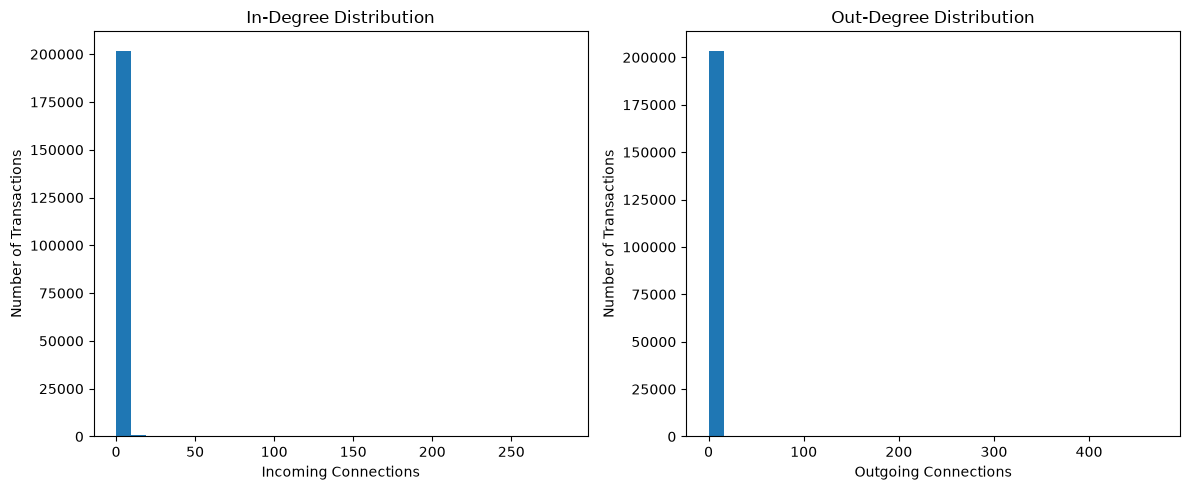

In [45]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(graph_features["in_degree"], bins=30)
plt.title("In-Degree Distribution")
plt.xlabel("Incoming Connections")
plt.ylabel("Number of Transactions")

plt.subplot(1, 2, 2)
plt.hist(graph_features["out_degree"], bins=30)
plt.title("Out-Degree Distribution")
plt.xlabel("Outgoing Connections")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

In [46]:
graph_features.to_csv(
    "../elliptic_bitcoin_dataset/graph_features_exploratory.csv",
    index=False
)

print("Exploratory graph features saved successfully!")

Exploratory graph features saved successfully!


In [47]:
# Ensure transaction IDs and labels have consistent formats
classes["txId"] = classes["txId"].astype(str).str.strip()
classes["class"] = classes["class"].astype(str).str.strip()

# Combine graph features with transaction labels
graph_labeled = graph_features.merge(
    classes,
    on="txId",
    how="left",
    validate="one_to_one"
)

print("Merged dataset shape:", graph_labeled.shape)
print("\nClass distribution:")
print(graph_labeled["class"].value_counts())

Merged dataset shape: (203769, 5)

Class distribution:
class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64


In [48]:
# Compare only the labelled transactions
known_graph = graph_labeled[
    graph_labeled["class"].isin(["1", "2"])
].copy()

# Display descriptive statistics
comparison = known_graph.groupby("class")[
    ["in_degree", "out_degree", "pagerank"]
].agg(["mean", "median", "max"])

comparison = comparison.rename(
    index={"1": "Illicit", "2": "Licit"}
)

print(comparison)

        in_degree             out_degree              pagerank            \
             mean median  max       mean median  max      mean    median   
class                                                                      
Illicit  1.269967    1.0  177   0.741694    1.0    3  0.000004  0.000003   
Licit    1.909398    1.0  284   1.185821    1.0  472  0.000006  0.000003   

                   
              max  
class              
Illicit  0.000406  
Licit    0.000527  


C:\Users\Tejaswini.K\AppData\Local\Temp\ipykernel_12240\2057890720.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["Illicit", "Licit"])
C:\Users\Tejaswini.K\AppData\Local\Temp\ipykernel_12240\2057890720.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(["Illicit", "Licit"])


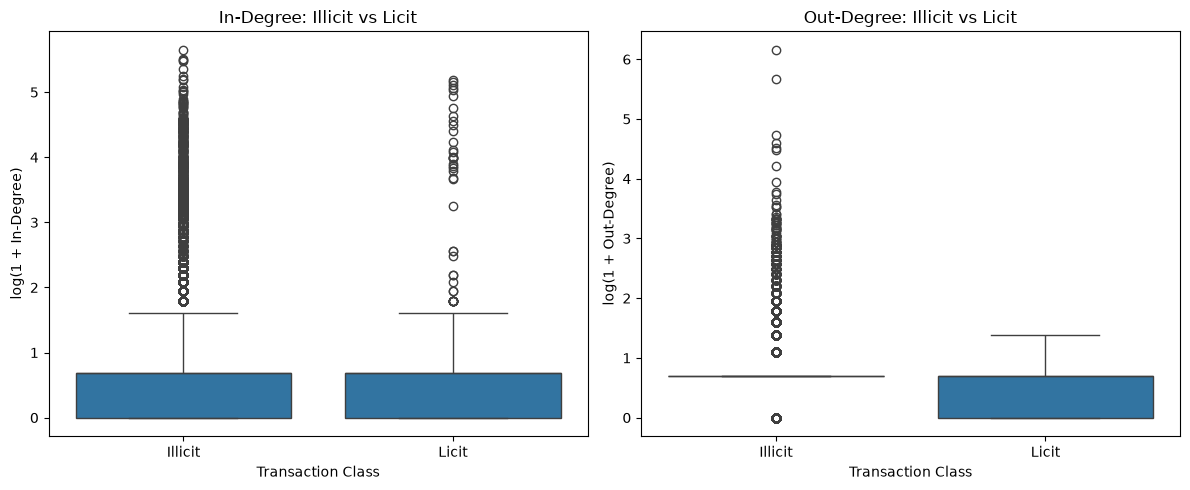

In [49]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

known_graph["log_in_degree"] = np.log1p(
    known_graph["in_degree"]
)

known_graph["log_out_degree"] = np.log1p(
    known_graph["out_degree"]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=known_graph,
    x="class",
    y="log_in_degree",
    ax=axes[0]
)

axes[0].set_title("In-Degree: Illicit vs Licit")
axes[0].set_xticklabels(["Illicit", "Licit"])
axes[0].set_xlabel("Transaction Class")
axes[0].set_ylabel("log(1 + In-Degree)")

sns.boxplot(
    data=known_graph,
    x="class",
    y="log_out_degree",
    ax=axes[1]
)

axes[1].set_title("Out-Degree: Illicit vs Licit")
axes[1].set_xticklabels(["Illicit", "Licit"])
axes[1].set_xlabel("Transaction Class")
axes[1].set_ylabel("log(1 + Out-Degree)")

plt.tight_layout()
plt.show()

In [50]:
graph_labeled.to_csv(
    "../elliptic_bitcoin_dataset/graph_features_labeled.csv",
    index=False
)

print("Labelled graph features saved successfully!")

Labelled graph features saved successfully!


In [51]:
# Create a mapping between transaction IDs and time steps
time_map = features.set_index("txId")["time_step"]

# Copy the edge dataset
temporal_edges = edges.copy()

# Add time steps for both endpoints
temporal_edges["source_time"] = (
    temporal_edges["txId1"].map(time_map)
)

temporal_edges["destination_time"] = (
    temporal_edges["txId2"].map(time_map)
)

# Calculate the time difference
temporal_edges["time_difference"] = (
    temporal_edges["destination_time"] -
    temporal_edges["source_time"]
)

print("Temporal edge dataset:")
print(temporal_edges.head())

Temporal edge dataset:
       txId1      txId2  source_time  destination_time  time_difference
1  230425980    5530458            1                 1                0
2  232022460  232438397            1                 1                0
3  230460314  230459870            1                 1                0
4  230333930  230595899            1                 1                0
5  232013274  232029206            1                 1                0


In [52]:
print("Time difference statistics:")
print(temporal_edges["time_difference"].describe())

print("\nTime difference distribution:")
print(
    temporal_edges["time_difference"]
    .value_counts()
    .sort_index()
    .head(20)
)

Time difference statistics:
count    234355.0
mean          0.0
std           0.0
min           0.0
25%           0.0
50%           0.0
75%           0.0
max           0.0
Name: time_difference, dtype: float64

Time difference distribution:
time_difference
0    234355
Name: count, dtype: int64


In [53]:
same_time_edges = (
    temporal_edges["time_difference"] == 0
).sum()

cross_time_edges = (
    temporal_edges["time_difference"] != 0
).sum()

print("Total edges:", len(temporal_edges))
print("Same-time-step edges:", same_time_edges)
print("Cross-time-step edges:", cross_time_edges)

print(
    "Edges with missing time information:",
    temporal_edges[
        ["source_time", "destination_time"]
    ].isna().any(axis=1).sum()
)

Total edges: 234355
Same-time-step edges: 234355
Cross-time-step edges: 0
Edges with missing time information: 0


In [54]:
import networkx as nx
import pandas as pd

time_aware_features = []

# Group transactions and edges by time step
transactions_by_time = features.groupby("time_step")
edges_by_time = temporal_edges.groupby("source_time")

# Process each time step separately
for time_step, transaction_group in transactions_by_time:

    # Create a separate directed graph
    G_time = nx.DiGraph()

    # Add all transactions belonging to this time step
    G_time.add_nodes_from(transaction_group["txId"])

    # Get edges belonging to the same time step
    if time_step in edges_by_time.groups:
        edge_group = edges_by_time.get_group(time_step)

        G_time.add_edges_from(
            edge_group[["txId1", "txId2"]]
            .itertuples(index=False, name=None)
        )

    # Calculate degree features
    in_degree = dict(G_time.in_degree())
    out_degree = dict(G_time.out_degree())

    # Calculate PageRank for this time-step network
    pagerank_scores = nx.pagerank(
        G_time,
        alpha=0.85,
        max_iter=100,
        tol=1e-6
    )

    # Store results
    step_features = pd.DataFrame({
        "txId": list(G_time.nodes()),
        "time_step": time_step,
        "in_degree": [in_degree[node] for node in G_time.nodes()],
        "out_degree": [out_degree[node] for node in G_time.nodes()],
        "pagerank": [
            pagerank_scores[node] for node in G_time.nodes()
        ]
    })

    time_aware_features.append(step_features)

    print(f"Completed time step {time_step}")

# Combine all time-step features
time_aware_features = pd.concat(
    time_aware_features,
    ignore_index=True
)

print("\nTime-aware graph features created!")
print("Dataset shape:", time_aware_features.shape)
print(time_aware_features.head())

Completed time step 1
Completed time step 2
Completed time step 3
Completed time step 4
Completed time step 5
Completed time step 6
Completed time step 7
Completed time step 8
Completed time step 9
Completed time step 10
Completed time step 11
Completed time step 12
Completed time step 13
Completed time step 14
Completed time step 15
Completed time step 16
Completed time step 17
Completed time step 18
Completed time step 19
Completed time step 20
Completed time step 21
Completed time step 22
Completed time step 23
Completed time step 24
Completed time step 25
Completed time step 26
Completed time step 27
Completed time step 28
Completed time step 29
Completed time step 30
Completed time step 31
Completed time step 32
Completed time step 33
Completed time step 34
Completed time step 35
Completed time step 36
Completed time step 37
Completed time step 38
Completed time step 39
Completed time step 40
Completed time step 41
Completed time step 42
Completed time step 43
Completed time step 

In [55]:
print("Original transactions:", len(features))
print("New graph feature rows:", len(time_aware_features))

print(
    "Duplicate transaction IDs:",
    time_aware_features["txId"].duplicated().sum()
)

print(
    "Missing values:",
    time_aware_features.isnull().sum().sum()
)

print(
    "Unique time steps:",
    time_aware_features["time_step"].nunique()
)

print("\nTransactions per time step:")
print(time_aware_features["time_step"].value_counts().sort_index())

Original transactions: 203769
New graph feature rows: 203769
Duplicate transaction IDs: 0
Missing values: 0
Unique time steps: 49

Transactions per time step:
time_step
1     7880
2     4544
3     6621
4     5693
5     6803
6     4328
7     6048
8     4457
9     4996
10    6727
11    4296
12    2047
13    4528
14    2022
15    3639
16    2975
17    3385
18    1976
19    3506
20    4291
21    3537
22    5894
23    4165
24    4592
25    2314
26    2523
27    1089
28    1653
29    4275
30    2483
31    2816
32    4525
33    3151
34    2486
35    5507
36    6393
37    3306
38    2891
39    2760
40    4481
41    5342
42    7140
43    5063
44    4975
45    5598
46    3519
47    5121
48    2954
49    2454
Name: count, dtype: int64


In [56]:
time_aware_features.to_csv(
    "../elliptic_bitcoin_dataset/time_aware_graph_features.csv",
    index=False
)

print("Time-aware graph features saved successfully!")

Time-aware graph features saved successfully!


In [57]:
hybrid_data = features.merge(
    time_aware_features,
    on=["txId", "time_step"],
    how="inner",
    validate="one_to_one"
)

print("Hybrid dataset shape:", hybrid_data.shape)
print(hybrid_data.head())

Hybrid dataset shape: (203769, 170)
        txId  time_step  feature_1  feature_2  feature_3  feature_4  \
0  230425980          1  -0.171469  -0.184668  -1.201369  -0.121970   
1    5530458          1  -0.171484  -0.184668  -1.201369  -0.121970   
2  232022460          1  -0.172107  -0.184668  -1.201369  -0.121970   
3  232438397          1   0.163054   1.963790  -0.646376  12.409294   
4  230460314          1   1.011523  -0.081127  -1.201369   1.153668   

   feature_5  feature_6  feature_7  feature_8  ...  feature_159  feature_160  \
0  -0.043875  -0.113002  -0.061584  -0.162097  ...     1.461369     0.018279   
1  -0.043875  -0.113002  -0.061584  -0.162112  ...    -0.978556     0.018279   
2  -0.043875  -0.113002  -0.061584  -0.162749  ...    -0.978556    -0.098889   
3  -0.063725   9.782742  12.414558  -0.163645  ...     0.241406     1.072793   
4   0.333276   1.312656  -0.061584  -0.163523  ...     0.579382     0.018279   

   feature_161  feature_162  feature_163  feature_164  f

In [58]:
# Merge transaction labels with hybrid features
hybrid_labeled = hybrid_data.merge(
    classes,
    on="txId",
    how="left",
    validate="one_to_one"
)

print("Hybrid labelled dataset shape:", hybrid_labeled.shape)

print("\nClass distribution:")
print(hybrid_labeled["class"].value_counts())

Hybrid labelled dataset shape: (203769, 171)

Class distribution:
class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64


In [59]:
# Transactions with known labels
known_hybrid = hybrid_labeled[
    hybrid_labeled["class"].isin(["1", "2"])
].copy()

# Transactions without known labels
unknown_hybrid = hybrid_labeled[
    hybrid_labeled["class"] == "unknown"
].copy()

print("Known transactions:", len(known_hybrid))
print("Unknown transactions:", len(unknown_hybrid))

print("\nKnown class distribution:")
print(known_hybrid["class"].value_counts())

Known transactions: 46564
Unknown transactions: 157205

Known class distribution:
class
2    42019
1     4545
Name: count, dtype: int64


In [60]:
# Training data
train_data = known_hybrid[
    known_hybrid["time_step"].between(1, 30)
].copy()

# Validation data
val_data = known_hybrid[
    known_hybrid["time_step"].between(31, 38)
].copy()

# Testing data
test_data = known_hybrid[
    known_hybrid["time_step"].between(39, 49)
].copy()

print("Training shape:", train_data.shape)
print("Validation shape:", val_data.shape)
print("Testing shape:", test_data.shape)


Training shape: (26905, 171)
Validation shape: (7292, 171)
Testing shape: (12367, 171)


In [61]:
print("TRAINING CLASS DISTRIBUTION")
print(train_data["class"].value_counts())

print("\nVALIDATION CLASS DISTRIBUTION")
print(val_data["class"].value_counts())

print("\nTESTING CLASS DISTRIBUTION")
print(test_data["class"].value_counts())

TRAINING CLASS DISTRIBUTION
class
2    23951
1     2954
Name: count, dtype: int64

VALIDATION CLASS DISTRIBUTION
class
2    6418
1     874
Name: count, dtype: int64

TESTING CLASS DISTRIBUTION
class
2    11650
1      717
Name: count, dtype: int64


In [62]:
train_ids = set(train_data["txId"])
val_ids = set(val_data["txId"])
test_ids = set(test_data["txId"])

print("Train-Val overlap:", len(train_ids & val_ids))
print("Train-Test overlap:", len(train_ids & test_ids))
print("Val-Test overlap:", len(val_ids & test_ids))

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [63]:
import os

output_folder = "../elliptic_bitcoin_dataset/processed"

os.makedirs(output_folder, exist_ok=True)

train_data.to_csv(
    os.path.join(output_folder, "train_data.csv"),
    index=False
)

val_data.to_csv(
    os.path.join(output_folder, "validation_data.csv"),
    index=False
)

test_data.to_csv(
    os.path.join(output_folder, "test_data.csv"),
    index=False
)

unknown_hybrid.to_csv(
    os.path.join(output_folder, "unknown_data.csv"),
    index=False
)

print("All datasets saved successfully!")

All datasets saved successfully!


In [64]:
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

import matplotlib.pyplot as plt
import seaborn as sns

In [65]:
# Select numerical features
feature_columns = (
    [f"feature_{i}" for i in range(1, 166)] +
    ["in_degree", "out_degree", "pagerank"]
)

# Prepare training features
X_train = train_data[feature_columns]
y_train = train_data["class"].map({
    "1": 1,
    "2": 0
})

# Prepare validation features
X_val = val_data[feature_columns]
y_val = val_data["class"].map({
    "1": 1,
    "2": 0
})

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("\nTraining labels:")
print(y_train.value_counts())

print("\nValidation labels:")
print(y_val.value_counts())

Training features: (26905, 168)
Validation features: (7292, 168)

Training labels:
class
0    23951
1     2954
Name: count, dtype: int64

Validation labels:
class
0    6418
1     874
Name: count, dtype: int64


In [66]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),

    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [67]:
# Predict validation labels
y_val_pred = logistic_model.predict(X_val)

# Get probability of illicit class
y_val_prob = logistic_model.predict_proba(X_val)[:, 1]

print("Predictions completed!")

print("\nFirst 10 actual labels:")
print(y_val.iloc[:10].values)

print("\nFirst 10 predicted labels:")
print(y_val_pred[:10])

Predictions completed!

First 10 actual labels:
[0 0 0 0 0 0 0 1 0 0]

First 10 predicted labels:
[0 0 0 0 0 0 1 1 1 0]


In [68]:
print("CLASSIFICATION REPORT")
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["Licit", "Illicit"],
        zero_division=0
    )
)

print("Average Precision (PR-AUC):",
      average_precision_score(y_val, y_val_prob))

print("Precision:",
      precision_score(y_val, y_val_pred, zero_division=0))

print("Recall:",
      recall_score(y_val, y_val_pred, zero_division=0))

print("F1 Score:",
      f1_score(y_val, y_val_pred, zero_division=0))

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Licit       1.00      0.65      0.79      6418
     Illicit       0.27      0.98      0.43       874

    accuracy                           0.69      7292
   macro avg       0.63      0.81      0.61      7292
weighted avg       0.91      0.69      0.74      7292

Average Precision (PR-AUC): 0.45241892820754825
Precision: 0.27450980392156865
Recall: 0.977116704805492
F1 Score: 0.4286072772898369


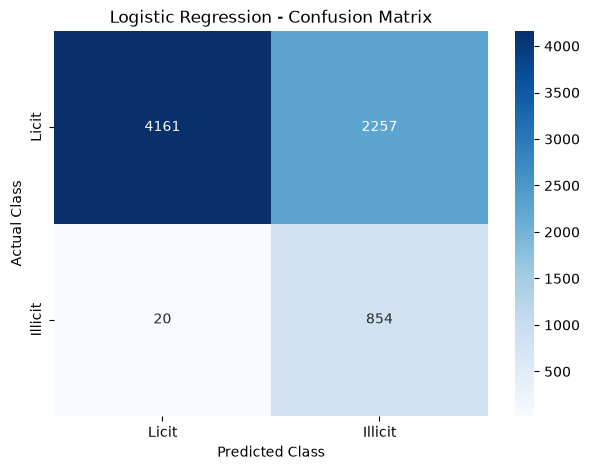

In [69]:
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Licit", "Illicit"],
    yticklabels=["Licit", "Illicit"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

In [70]:
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

In [71]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [72]:
rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [73]:
# Predict validation labels
y_val_pred_rf = rf_model.predict(X_val)

# Get illicit transaction probabilities
y_val_prob_rf = rf_model.predict_proba(X_val)[:, 1]

print("Random Forest predictions completed!")

Random Forest predictions completed!


In [74]:
print("RANDOM FOREST CLASSIFICATION REPORT")

print(
    classification_report(
        y_val,
        y_val_pred_rf,
        target_names=["Licit", "Illicit"],
        zero_division=0
    )
)

print(
    "Average Precision:",
    average_precision_score(y_val, y_val_prob_rf)
)

print(
    "Precision:",
    precision_score(y_val, y_val_pred_rf, zero_division=0)
)

print(
    "Recall:",
    recall_score(y_val, y_val_pred_rf, zero_division=0)
)

print(
    "F1 Score:",
    f1_score(y_val, y_val_pred_rf, zero_division=0)
)

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Licit       0.99      1.00      0.99      6418
     Illicit       1.00      0.92      0.96       874

    accuracy                           0.99      7292
   macro avg       0.99      0.96      0.98      7292
weighted avg       0.99      0.99      0.99      7292

Average Precision: 0.9791419384015931
Precision: 0.995049504950495
Recall: 0.919908466819222
F1 Score: 0.9560047562425684


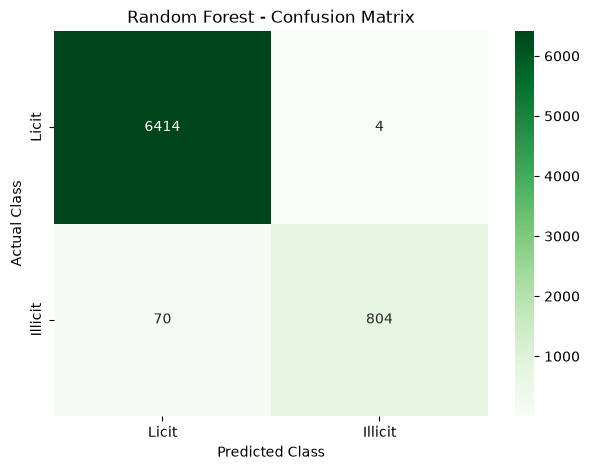

In [75]:
cm_rf = confusion_matrix(y_val, y_val_pred_rf)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Licit", "Illicit"],
    yticklabels=["Licit", "Illicit"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Random Forest - Confusion Matrix")

plt.show()

In [76]:
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],

    "Precision": [
        precision_score(y_val, logistic_model.predict(X_val)),
        precision_score(y_val, y_val_pred_rf)
    ],

    "Recall": [
        recall_score(y_val, logistic_model.predict(X_val)),
        recall_score(y_val, y_val_pred_rf)
    ],

    "F1 Score": [
        f1_score(y_val, logistic_model.predict(X_val)),
        f1_score(y_val, y_val_pred_rf)
    ],

    "Average Precision": [
        average_precision_score(
            y_val, logistic_model.predict_proba(X_val)[:, 1]
        ),
        average_precision_score(y_val, y_val_prob_rf)
    ]
})

print(model_comparison)

                 Model  Precision    Recall  F1 Score  Average Precision
0  Logistic Regression    0.27451  0.977117  0.428607           0.452419
1        Random Forest    0.99505  0.919908  0.956005           0.979142


In [77]:
%pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [78]:
import xgboost as xgb

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [79]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_weight = negative_count / positive_count

print("Licit transactions:", negative_count)
print("Illicit transactions:", positive_count)
print("Scale positive weight:", scale_weight)

Licit transactions: 23951
Illicit transactions: 2954
Scale positive weight: 8.107989167230873


In [80]:
xgb_model = xgb.XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

print("XGBoost model created successfully!")

XGBoost model created successfully!


In [81]:
xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [82]:
y_val_pred_xgb = xgb_model.predict(X_val)

y_val_prob_xgb = xgb_model.predict_proba(X_val)[:, 1]

print("XGBoost predictions completed!")

XGBoost predictions completed!


In [83]:
print("XGBOOST CLASSIFICATION REPORT")

print(
    classification_report(
        y_val,
        y_val_pred_xgb,
        target_names=["Licit", "Illicit"],
        zero_division=0
    )
)

print(
    "Average Precision:",
    average_precision_score(y_val, y_val_prob_xgb)
)

print(
    "Precision:",
    precision_score(y_val, y_val_pred_xgb, zero_division=0)
)

print(
    "Recall:",
    recall_score(y_val, y_val_pred_xgb, zero_division=0)
)

print(
    "F1 Score:",
    f1_score(y_val, y_val_pred_xgb, zero_division=0)
)

XGBOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Licit       0.99      0.99      0.99      6418
     Illicit       0.93      0.96      0.94       874

    accuracy                           0.99      7292
   macro avg       0.96      0.97      0.97      7292
weighted avg       0.99      0.99      0.99      7292

Average Precision: 0.9809219905761487
Precision: 0.9298440979955457
Recall: 0.9553775743707094
F1 Score: 0.9424379232505643


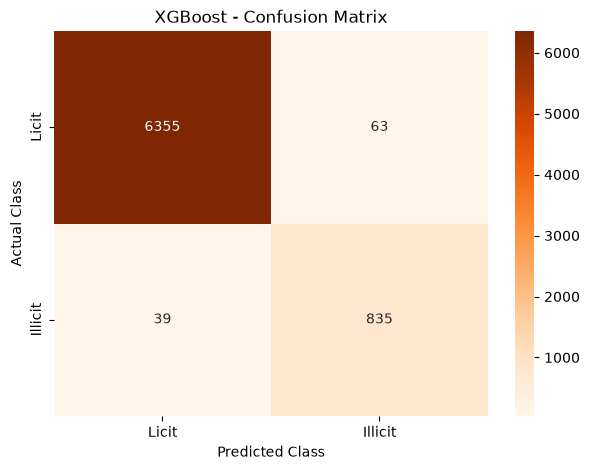

In [84]:
cm_xgb = confusion_matrix(y_val, y_val_pred_xgb)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Licit", "Illicit"],
    yticklabels=["Licit", "Illicit"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("XGBoost - Confusion Matrix")

plt.show()

In [85]:
final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],

    "Precision": [
        precision_score(y_val, logistic_model.predict(X_val)),
        precision_score(y_val, y_val_pred_rf),
        precision_score(y_val, y_val_pred_xgb)
    ],

    "Recall": [
        recall_score(y_val, logistic_model.predict(X_val)),
        recall_score(y_val, y_val_pred_rf),
        recall_score(y_val, y_val_pred_xgb)
    ],

    "F1 Score": [
        f1_score(y_val, logistic_model.predict(X_val)),
        f1_score(y_val, y_val_pred_rf),
        f1_score(y_val, y_val_pred_xgb)
    ],

    "Average Precision": [
        average_precision_score(
            y_val, logistic_model.predict_proba(X_val)[:, 1]
        ),
        average_precision_score(y_val, y_val_prob_rf),
        average_precision_score(y_val, y_val_prob_xgb)
    ]
})

print(final_comparison)

                 Model  Precision    Recall  F1 Score  Average Precision
0  Logistic Regression   0.274510  0.977117  0.428607           0.452419
1        Random Forest   0.995050  0.919908  0.956005           0.979142
2              XGBoost   0.929844  0.955378  0.942438           0.980922


In [86]:
%pip install torch torch-geometric

   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.5/126.7 MB 2.5 MB/s eta 0:00:51
   ---------------------------------------- 1.0/126.7 MB 2.6 MB/s eta 0:00:48
   ---------------------------------------- 1.6/126.7 MB 2.8 MB/s eta 0:00:46
    --------------------------------------- 2.1/126.7 MB 2.7 MB/s eta 0:00:47
    --------------------------------------- 2.9/126.7 MB 2.8 MB/s eta 0:00:45
   - -------------------------------------- 3.4/126.7 MB 2.8 MB/s eta 0:00:44
   - -------------------------------------- 3.9/126.7 MB 2.7 MB/s eta 0:00:46
   - -------------------------------------- 3.9/126.7 MB 2.7 MB/s eta 0:00:46
   - -------------------------------------- 3.9/126.7 MB 2.7 MB/s eta 0:00:46
   - -------------------------------------- 4.2/126.7 MB 2.1 MB/s eta 0:00:59
   - -------------------------------------- 4.2/126.7 MB 2.1 MB/s eta 0:00:59
   - -------------------------------------- 4.5/126.7 MB 1.7 MB/s eta 0


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [87]:
import torch
import torch.nn.functional as F

from torch_geometric.data import Data
from torch_geometric.nn import GCNConv

print("PyTorch version:", torch.__version__)
print("PyTorch Geometric imported successfully!")
print("GPU available:", torch.cuda.is_available())

c:\Users\Tejaswini.K\OneDrive\Desktop\mini project\venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PyTorch version: 2.15.0+cpu
PyTorch Geometric imported successfully!
GPU available: False


In [88]:
print("Features shape:", features.shape)
print("Edges shape:", edges.shape)

print("Training transactions:", len(train_data))
print("Validation transactions:", len(val_data))
print("Testing transactions:", len(test_data))

print("\nTraining class distribution:")
print(train_data["class"].value_counts())

Features shape: (203769, 167)
Edges shape: (234355, 2)
Training transactions: 26905
Validation transactions: 7292
Testing transactions: 12367

Training class distribution:
class
2    23951
1     2954
Name: count, dtype: int64


In [89]:
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import networkx as nx

from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
from torch_geometric.utils import to_undirected

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.15.0+cpu
CUDA available: False


In [90]:
# Select the 165 original numerical features
original_feature_columns = [
    f"feature_{i}" for i in range(1, 166)
]

# Convert features into a PyTorch tensor
X = torch.tensor(
    features[original_feature_columns].to_numpy(dtype=np.float32),
    dtype=torch.float32
)

print("Feature tensor shape:", X.shape)
print("Feature tensor data type:", X.dtype)

Feature tensor shape: torch.Size([203769, 165])
Feature tensor data type: torch.float32


In [91]:
# Map each transaction ID to a unique integer
node_mapping = {
    tx_id: index
    for index, tx_id in enumerate(features["txId"])
}

print("Total mapped nodes:", len(node_mapping))

Total mapped nodes: 203769


In [92]:
# Convert transaction IDs into integer indices
source_nodes = edges["txId1"].map(node_mapping).to_numpy()
destination_nodes = edges["txId2"].map(node_mapping).to_numpy()

# Create edge index tensor
edge_index = torch.tensor(
    np.vstack([source_nodes, destination_nodes]),
    dtype=torch.long
)

# Make connections bidirectional for the standard GCN
edge_index = to_undirected(
    edge_index,
    num_nodes=len(features)
)

print("Edge index shape:", edge_index.shape)
print("Total graph connections:", edge_index.shape[1])


Edge index shape: torch.Size([2, 468710])
Total graph connections: 468710


In [93]:
# Match labels to the same transaction order as features
label_map = classes.set_index("txId")["class"]

ordered_labels = features["txId"].map(label_map)

y = torch.tensor(
    ordered_labels.map({
        "1": 1,
        "2": 0,
        "unknown": -1
    }).to_numpy(dtype=np.int64),
    dtype=torch.long
)

print("Label tensor shape:", y.shape)
print("Licit:", (y == 0).sum().item())
print("Illicit:", (y == 1).sum().item())
print("Unknown:", (y == -1).sum().item())

Label tensor shape: torch.Size([203769])
Licit: 42019
Illicit: 4545
Unknown: 157205


In [94]:
time_steps = features["time_step"].to_numpy()

train_mask = torch.tensor(
    np.isin(time_steps, range(1, 31)) & (y.numpy() != -1)
)

val_mask = torch.tensor(
    np.isin(time_steps, range(31, 39)) & (y.numpy() != -1)
)

test_mask = torch.tensor(
    np.isin(time_steps, range(39, 50)) & (y.numpy() != -1)
)

print("Training nodes:", train_mask.sum().item())
print("Validation nodes:", val_mask.sum().item())
print("Testing nodes:", test_mask.sum().item())

Training nodes: 26905
Validation nodes: 7292
Testing nodes: 12367


In [95]:
data = Data(
    x=X,
    edge_index=edge_index,
    y=y,
    train_mask=train_mask,
    val_mask=val_mask,
    test_mask=test_mask
)

print("\nGCN graph data created successfully!")
print(data)


GCN graph data created successfully!
Data(x=[203769, 165], edge_index=[2, 468710], y=[203769], train_mask=[203769], val_mask=[203769], test_mask=[203769])


In [96]:
print("Training class counts:")
print("Licit:", (y[train_mask] == 0).sum().item())
print("Illicit:", (y[train_mask] == 1).sum().item())

print("\nValidation class counts:")
print("Licit:", (y[val_mask] == 0).sum().item())
print("Illicit:", (y[val_mask] == 1).sum().item())

print("\nTesting class counts:")
print("Licit:", (y[test_mask] == 0).sum().item())
print("Illicit:", (y[test_mask] == 1).sum().item())

Training class counts:
Licit: 23951
Illicit: 2954

Validation class counts:
Licit: 6418
Illicit: 874

Testing class counts:
Licit: 11650
Illicit: 717


In [97]:
class GCN(torch.nn.Module):

    def __init__(self, input_features, hidden_features, num_classes):
        super(GCN, self).__init__()

        # First graph convolution layer
        self.conv1 = GCNConv(input_features, hidden_features)

        # Second graph convolution layer
        self.conv2 = GCNConv(hidden_features, num_classes)

    def forward(self, x, edge_index):

        # First graph convolution
        x = self.conv1(x, edge_index)
        x = F.relu(x)

        # Dropout to reduce overfitting
        x = F.dropout(x, p=0.5, training=self.training)

        # Second graph convolution
        x = self.conv2(x, edge_index)

        return x

In [98]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

model = GCN(
    input_features=165,
    hidden_features=64,
    num_classes=2
).to(device)

data = data.to(device)

print(model)

Using device: cpu
GCN(
  (conv1): GCNConv(165, 64)
  (conv2): GCNConv(64, 2)
)


In [99]:
train_labels = data.y[data.train_mask]

class_counts = torch.bincount(
    train_labels,
    minlength=2
).float()

class_weights = (
    class_counts.sum() / (2 * class_counts)
)

class_weights = class_weights.to(device)

print("Class counts:", class_counts)
print("Class weights:", class_weights)

Class counts: tensor([23951.,  2954.])
Class weights: tensor([0.5617, 4.5540])


In [100]:
import torch.optim as optim

criterion = torch.nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=5e-4
)

print("GCN training configuration completed!")

GCN training configuration completed!


In [101]:
from sklearn.metrics import average_precision_score

epochs = 100

for epoch in range(1, epochs + 1):

    model.train()
    optimizer.zero_grad()

    # Forward pass
    output = model(data.x, data.edge_index)

    # Calculate loss only on training nodes
    loss = criterion(
        output[data.train_mask],
        data.y[data.train_mask]
    )

    # Backpropagation
    loss.backward()
    optimizer.step()

    # Validation
    model.eval()

    with torch.no_grad():
        val_output = model(data.x, data.edge_index)

        val_prob = torch.softmax(
            val_output[data.val_mask],
            dim=1
        )[:, 1]

        val_ap = average_precision_score(
            data.y[data.val_mask].cpu().numpy(),
            val_prob.cpu().numpy()
        )

    if epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Loss: {loss.item():.4f} | "
            f"Validation AP: {val_ap:.4f}"
        )

print("\nGCN training completed!")

Epoch 010 | Loss: 0.2827 | Validation AP: 0.5462
Epoch 020 | Loss: 0.2339 | Validation AP: 0.6221
Epoch 030 | Loss: 0.2030 | Validation AP: 0.6102
Epoch 040 | Loss: 0.1842 | Validation AP: 0.5473
Epoch 050 | Loss: 0.1702 | Validation AP: 0.5687
Epoch 060 | Loss: 0.1636 | Validation AP: 0.5903
Epoch 070 | Loss: 0.1538 | Validation AP: 0.6269
Epoch 080 | Loss: 0.1445 | Validation AP: 0.6581
Epoch 090 | Loss: 0.1375 | Validation AP: 0.6642
Epoch 100 | Loss: 0.1334 | Validation AP: 0.6803

GCN training completed!


In [102]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

model.eval()

with torch.no_grad():

    output = model(data.x, data.edge_index)

    val_predictions = output[data.val_mask].argmax(dim=1)

    val_probabilities = torch.softmax(
        output[data.val_mask],
        dim=1
    )[:, 1]

y_val_gcn = data.y[data.val_mask].cpu().numpy()

y_pred_gcn = val_predictions.cpu().numpy()

y_prob_gcn = val_probabilities.cpu().numpy()

print("GCN CLASSIFICATION REPORT")

print(
    classification_report(
        y_val_gcn,
        y_pred_gcn,
        target_names=["Licit", "Illicit"],
        zero_division=0
    )
)

print(
    "Average Precision:",
    average_precision_score(y_val_gcn, y_prob_gcn)
)

print(
    "Precision:",
    precision_score(y_val_gcn, y_pred_gcn, zero_division=0)
)

print(
    "Recall:",
    recall_score(y_val_gcn, y_pred_gcn, zero_division=0)
)

print(
    "F1 Score:",
    f1_score(y_val_gcn, y_pred_gcn, zero_division=0)
)

GCN CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Licit       0.99      0.81      0.89      6418
     Illicit       0.40      0.93      0.56       874

    accuracy                           0.83      7292
   macro avg       0.70      0.87      0.73      7292
weighted avg       0.92      0.83      0.85      7292

Average Precision: 0.6802725573829137
Precision: 0.4021685559388862
Recall: 0.9336384439359268
F1 Score: 0.562177058215639


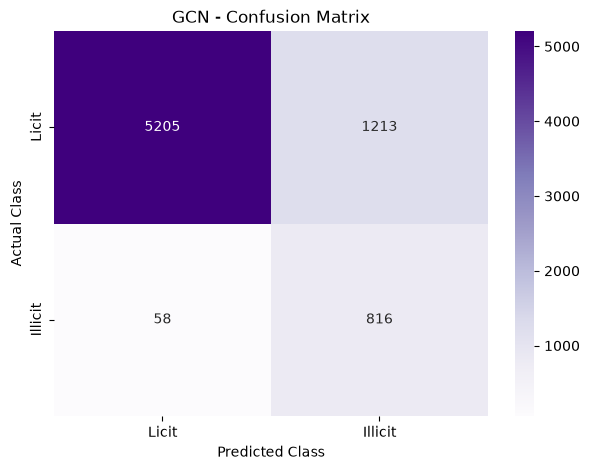

In [103]:
cm_gcn = confusion_matrix(
    y_val_gcn,
    y_pred_gcn
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_gcn,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Licit", "Illicit"],
    yticklabels=["Licit", "Illicit"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("GCN - Confusion Matrix")

plt.show()

In [104]:
model.eval()

with torch.no_grad():
    gcn_embeddings = model.conv1(
        data.x,
        data.edge_index
    )

    gcn_embeddings = F.relu(gcn_embeddings)

print("GCN embeddings shape:", gcn_embeddings.shape)

GCN embeddings shape: torch.Size([203769, 64])


In [105]:
embedding_array = gcn_embeddings.cpu().numpy()

embedding_columns = [
    f"gcn_embedding_{i}"
    for i in range(1, 65)
]

embedding_df = pd.DataFrame(
    embedding_array,
    columns=embedding_columns
)

# Preserve transaction ID for correct merging
embedding_df.insert(
    0,
    "txId",
    features["txId"].values
)

print("Embedding dataset shape:", embedding_df.shape)
print(embedding_df.head())

Embedding dataset shape: (203769, 65)
        txId  gcn_embedding_1  gcn_embedding_2  gcn_embedding_3  \
0  230425980         0.675866         0.000000         0.000000   
1    5530458         0.113557         0.000000         0.294306   
2  232022460         0.000000         0.000000         0.448607   
3  232438397         0.000000         7.287073         8.597898   
4  230460314         0.252814         0.956800         0.000000   

   gcn_embedding_4  gcn_embedding_5  gcn_embedding_6  gcn_embedding_7  \
0         0.000000         0.031904         0.000000         0.000000   
1         0.000000         0.000000         0.000000         0.000000   
2         0.183110         0.000000         0.000000         0.000000   
3         6.857727         0.000000         0.000000         0.000000   
4         0.151936         0.000000         0.397553         0.802822   

   gcn_embedding_8  gcn_embedding_9  ...  gcn_embedding_55  gcn_embedding_56  \
0         0.246267         0.500786  ...

In [106]:
hybrid_gnn_data = hybrid_data.merge(
    embedding_df,
    on="txId",
    how="inner",
    validate="one_to_one"
)

hybrid_gnn_data = hybrid_gnn_data.merge(
    classes,
    on="txId",
    how="inner",
    validate="one_to_one"
)

print("Final hybrid dataset shape:", hybrid_gnn_data.shape)
print(hybrid_gnn_data.head())

Final hybrid dataset shape: (203769, 235)
        txId  time_step  feature_1  feature_2  feature_3  feature_4  \
0  230425980          1  -0.171469  -0.184668  -1.201369  -0.121970   
1    5530458          1  -0.171484  -0.184668  -1.201369  -0.121970   
2  232022460          1  -0.172107  -0.184668  -1.201369  -0.121970   
3  232438397          1   0.163054   1.963790  -0.646376  12.409294   
4  230460314          1   1.011523  -0.081127  -1.201369   1.153668   

   feature_5  feature_6  feature_7  feature_8  ...  gcn_embedding_56  \
0  -0.043875  -0.113002  -0.061584  -0.162097  ...           0.00000   
1  -0.043875  -0.113002  -0.061584  -0.162112  ...           0.00000   
2  -0.043875  -0.113002  -0.061584  -0.162749  ...           0.00000   
3  -0.063725   9.782742  12.414558  -0.163645  ...           0.00000   
4   0.333276   1.312656  -0.061584  -0.163523  ...           0.56126   

   gcn_embedding_57  gcn_embedding_58  gcn_embedding_59  gcn_embedding_60  \
0               0.0  

In [107]:
# Select all 232 model input features
hybrid_feature_columns = (
    [f"feature_{i}" for i in range(1, 166)] +
    ["in_degree", "out_degree", "pagerank"] +
    embedding_columns
)

# Keep only known labels
known_hybrid_gnn = hybrid_gnn_data[
    hybrid_gnn_data["class"].isin(["1", "2"])
].copy()

# Chronological splits
train_hybrid = known_hybrid_gnn[
    known_hybrid_gnn["time_step"].between(1, 30)
].copy()

val_hybrid = known_hybrid_gnn[
    known_hybrid_gnn["time_step"].between(31, 38)
].copy()

# Prepare X and y
X_train_hybrid = train_hybrid[hybrid_feature_columns]

y_train_hybrid = train_hybrid["class"].map({
    "1": 1,
    "2": 0
})

X_val_hybrid = val_hybrid[hybrid_feature_columns]

y_val_hybrid = val_hybrid["class"].map({
    "1": 1,
    "2": 0
})

print("Hybrid training shape:", X_train_hybrid.shape)
print("Hybrid validation shape:", X_val_hybrid.shape)

print("\nTraining labels:")
print(y_train_hybrid.value_counts())

print("\nValidation labels:")
print(y_val_hybrid.value_counts())

Hybrid training shape: (26905, 232)
Hybrid validation shape: (7292, 232)

Training labels:
class
0    23951
1     2954
Name: count, dtype: int64

Validation labels:
class
0    6418
1     874
Name: count, dtype: int64


In [108]:
hybrid_scale_weight = (
    (y_train_hybrid == 0).sum() /
    (y_train_hybrid == 1).sum()
)

hybrid_xgb_model = xgb.XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=hybrid_scale_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

hybrid_xgb_model.fit(
    X_train_hybrid,
    y_train_hybrid,
    eval_set=[(X_val_hybrid, y_val_hybrid)],
    verbose=False
)

print("Hybrid GCN + XGBoost model trained successfully!")

Hybrid GCN + XGBoost model trained successfully!


In [109]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

y_val_pred_hybrid = hybrid_xgb_model.predict(
    X_val_hybrid
)

y_val_prob_hybrid = hybrid_xgb_model.predict_proba(
    X_val_hybrid
)[:, 1]

print("HYBRID GCN + XGBOOST CLASSIFICATION REPORT")

print(
    classification_report(
        y_val_hybrid,
        y_val_pred_hybrid,
        target_names=["Licit", "Illicit"],
        zero_division=0
    )
)

print(
    "Average Precision:",
    average_precision_score(
        y_val_hybrid,
        y_val_prob_hybrid
    )
)

print(
    "Precision:",
    precision_score(
        y_val_hybrid,
        y_val_pred_hybrid,
        zero_division=0
    )
)

print(
    "Recall:",
    recall_score(
        y_val_hybrid,
        y_val_pred_hybrid,
        zero_division=0
    )
)

print(
    "F1 Score:",
    f1_score(
        y_val_hybrid,
        y_val_pred_hybrid,
        zero_division=0
    )
)

HYBRID GCN + XGBOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Licit       0.99      0.99      0.99      6418
     Illicit       0.92      0.95      0.93       874

    accuracy                           0.98      7292
   macro avg       0.96      0.97      0.96      7292
weighted avg       0.98      0.98      0.98      7292

Average Precision: 0.9753027478916981
Precision: 0.9174008810572687
Recall: 0.9530892448512586
F1 Score: 0.9349046015712682


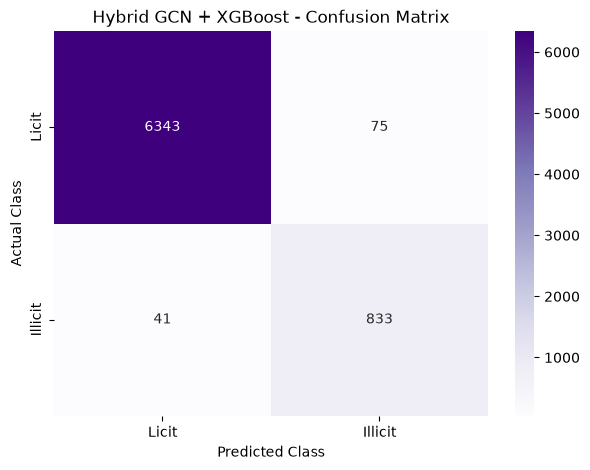

In [110]:
cm_hybrid = confusion_matrix(
    y_val_hybrid,
    y_val_pred_hybrid
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_hybrid,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Licit", "Illicit"],
    yticklabels=["Licit", "Illicit"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Hybrid GCN + XGBoost - Confusion Matrix")

plt.show()

In [111]:
comparison_all = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "GCN",
        "Hybrid GCN + XGBoost"
    ],

    "Precision": [
        precision_score(y_val, logistic_model.predict(X_val)),
        precision_score(y_val, y_val_pred_rf),
        precision_score(y_val, y_val_pred_xgb),
        precision_score(y_val_gcn, y_pred_gcn),
        precision_score(y_val_hybrid, y_val_pred_hybrid)
    ],

    "Recall": [
        recall_score(y_val, logistic_model.predict(X_val)),
        recall_score(y_val, y_val_pred_rf),
        recall_score(y_val, y_val_pred_xgb),
        recall_score(y_val_gcn, y_pred_gcn),
        recall_score(y_val_hybrid, y_val_pred_hybrid)
    ],

    "F1 Score": [
        f1_score(y_val, logistic_model.predict(X_val)),
        f1_score(y_val, y_val_pred_rf),
        f1_score(y_val, y_val_pred_xgb),
        f1_score(y_val_gcn, y_pred_gcn),
        f1_score(y_val_hybrid, y_val_pred_hybrid)
    ],

    "Average Precision": [
        average_precision_score(
            y_val, logistic_model.predict_proba(X_val)[:, 1]
        ),
        average_precision_score(y_val, y_val_prob_rf),
        average_precision_score(y_val, y_val_prob_xgb),
        average_precision_score(y_val_gcn, y_prob_gcn),
        average_precision_score(y_val_hybrid, y_val_prob_hybrid)
    ]
})

print(comparison_all.round(4))

                  Model  Precision  Recall  F1 Score  Average Precision
0   Logistic Regression     0.2745  0.9771    0.4286             0.4524
1         Random Forest     0.9950  0.9199    0.9560             0.9791
2               XGBoost     0.9298  0.9554    0.9424             0.9809
3                   GCN     0.4022  0.9336    0.5622             0.6803
4  Hybrid GCN + XGBoost     0.9174  0.9531    0.9349             0.9753


In [114]:
# Original + handcrafted graph features
X_test = test_data[feature_columns]

y_test = test_data["class"].map({
    "1": 1,
    "2": 0
})

print("Test feature shape:", X_test.shape)
print("\nTest class distribution:")
print(y_test.value_counts())

Test feature shape: (12367, 168)

Test class distribution:
class
0    11650
1      717
Name: count, dtype: int64


In [115]:
# Logistic Regression
pred_lr = logistic_model.predict(X_test)
prob_lr = logistic_model.predict_proba(X_test)[:, 1]

# Random Forest
pred_rf = rf_model.predict(X_test)
prob_rf = rf_model.predict_proba(X_test)[:, 1]

# XGBoost
pred_xgb = xgb_model.predict(X_test)
prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# GCN
model.eval()

with torch.no_grad():
    gcn_output = model(data.x, data.edge_index)

    pred_gcn = gcn_output[data.test_mask].argmax(dim=1).cpu().numpy()

    prob_gcn = torch.softmax(
        gcn_output[data.test_mask], dim=1
    )[:, 1].cpu().numpy()

y_test_gcn = data.y[data.test_mask].cpu().numpy()

# Hybrid GCN + XGBoost
pred_hybrid = hybrid_xgb_model.predict(X_test_hybrid)
prob_hybrid = hybrid_xgb_model.predict_proba(X_test_hybrid)[:, 1]

print("Predictions generated for all five models!")
print("Test samples:", len(y_test))
print("GCN test samples:", len(y_test_gcn))
print("Hybrid test samples:", len(y_test_hybrid))

Predictions generated for all five models!
Test samples: 12367
GCN test samples: 12367
Hybrid test samples: 12367


In [116]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    accuracy_score
)

test_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Precision": precision_score(y_test, pred_lr),
        "Recall": recall_score(y_test, pred_lr),
        "F1 Score": f1_score(y_test, pred_lr),
        "Average Precision": average_precision_score(y_test, prob_lr),
        "Accuracy": accuracy_score(y_test, pred_lr)
    },
    {
        "Model": "Random Forest",
        "Precision": precision_score(y_test, pred_rf),
        "Recall": recall_score(y_test, pred_rf),
        "F1 Score": f1_score(y_test, pred_rf),
        "Average Precision": average_precision_score(y_test, prob_rf),
        "Accuracy": accuracy_score(y_test, pred_rf)
    },
    {
        "Model": "XGBoost",
        "Precision": precision_score(y_test, pred_xgb),
        "Recall": recall_score(y_test, pred_xgb),
        "F1 Score": f1_score(y_test, pred_xgb),
        "Average Precision": average_precision_score(y_test, prob_xgb),
        "Accuracy": accuracy_score(y_test, pred_xgb)
    },
    {
        "Model": "GCN",
        "Precision": precision_score(y_test_gcn, pred_gcn),
        "Recall": recall_score(y_test_gcn, pred_gcn),
        "F1 Score": f1_score(y_test_gcn, pred_gcn),
        "Average Precision": average_precision_score(y_test_gcn, prob_gcn),
        "Accuracy": accuracy_score(y_test_gcn, pred_gcn)
    },
    {
        "Model": "Hybrid GCN + XGBoost",
        "Precision": precision_score(y_test_hybrid, pred_hybrid),
        "Recall": recall_score(y_test_hybrid, pred_hybrid),
        "F1 Score": f1_score(y_test_hybrid, pred_hybrid),
        "Average Precision": average_precision_score(y_test_hybrid, prob_hybrid),
        "Accuracy": accuracy_score(y_test_hybrid, pred_hybrid)
    }
])

print(test_comparison.round(4).to_string(index=False))

               Model  Precision  Recall  F1 Score  Average Precision  Accuracy
 Logistic Regression     0.1243  0.9205    0.2190             0.1739    0.6193
       Random Forest     0.9883  0.5900    0.7389             0.6977    0.9758
             XGBoost     0.6967  0.6471    0.6710             0.6983    0.9632
                 GCN     0.2021  0.6109    0.3037             0.3030    0.8376
Hybrid GCN + XGBoost     0.6696  0.6360    0.6524             0.6831    0.9607


In [117]:
test_comparison.to_csv(
    "../elliptic_bitcoin_dataset/processed/final_test_comparison.csv",
    index=False
)

print("Final test comparison saved successfully!")

Final test comparison saved successfully!


In [118]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

def evaluate_by_time(y_true, y_prob, time_values, model_name):

    results = []

    y_pred = (y_prob >= 0.5).astype(int)

    evaluation_data = pd.DataFrame({
        "time_step": np.asarray(time_values),
        "actual": np.asarray(y_true),
        "predicted": y_pred,
        "probability": np.asarray(y_prob)
    })

    for step, group in evaluation_data.groupby("time_step"):

        actual = group["actual"]
        predicted = group["predicted"]
        probability = group["probability"]

        results.append({
            "Model": model_name,
            "Time Step": step,
            "Transactions": len(group),
            "Illicit Transactions": int(actual.sum()),
            "Precision": precision_score(
                actual, predicted, zero_division=0
            ),
            "Recall": recall_score(
                actual, predicted, zero_division=0
            ),
            "F1 Score": f1_score(
                actual, predicted, zero_division=0
            ),
            "Average Precision": (
                average_precision_score(actual, probability)
                if actual.nunique() == 2 else np.nan
            )
        })

    return pd.DataFrame(results)

In [119]:
# XGBoost
xgb_time_results = evaluate_by_time(
    y_test,
    prob_xgb,
    test_data["time_step"],
    "XGBoost"
)

# Random Forest
rf_time_results = evaluate_by_time(
    y_test,
    prob_rf,
    test_data["time_step"],
    "Random Forest"
)

# Hybrid model
hybrid_time_results = evaluate_by_time(
    y_test_hybrid,
    prob_hybrid,
    test_hybrid["time_step"],
    "Hybrid GCN + XGBoost"
)

# Combine results
time_results = pd.concat(
    [
        xgb_time_results,
        rf_time_results,
        hybrid_time_results
    ],
    ignore_index=True
)

print(time_results.round(4).to_string(index=False))

               Model  Time Step  Transactions  Illicit Transactions  Precision  Recall  F1 Score  Average Precision
             XGBoost         39          1183                    81     0.8444  0.9383    0.8889             0.9522
             XGBoost         40          1211                   112     0.8041  0.6964    0.7464             0.7675
             XGBoost         41          1132                   116     0.8800  0.9483    0.9129             0.9636
             XGBoost         42          2154                   239     0.8661  0.8117    0.8380             0.8822
             XGBoost         43          1370                    24     0.0000  0.0000    0.0000             0.0353
             XGBoost         44          1591                    24     0.0517  0.1250    0.0732             0.0326
             XGBoost         45          1221                     5     0.0000  0.0000    0.0000             0.0077
             XGBoost         46           712                     2     

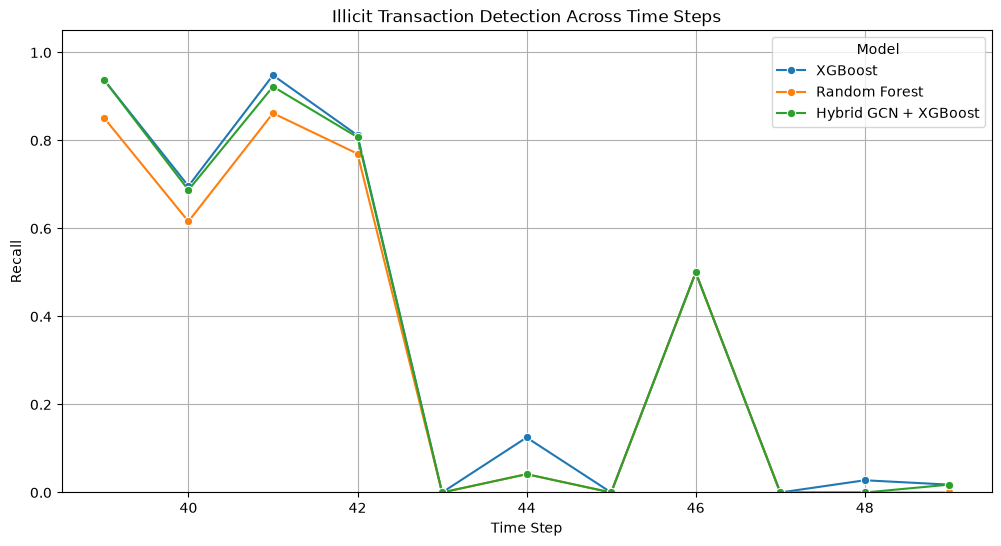

In [120]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=time_results,
    x="Time Step",
    y="Recall",
    hue="Model",
    marker="o"
)

plt.title("Illicit Transaction Detection Across Time Steps")
plt.xlabel("Time Step")
plt.ylabel("Recall")
plt.ylim(0, 1.05)
plt.grid(True)
plt.show()

In [121]:
time_results.to_csv(
    "../elliptic_bitcoin_dataset/processed/"
    "time_step_model_analysis.csv",
    index=False
)

print("Time-step analysis saved successfully!")

Time-step analysis saved successfully!


In [122]:
def time_step_diagnostics(y_true, y_prob, time_values, model_name):

    diagnostic = pd.DataFrame({
        "time_step": np.asarray(time_values),
        "actual": np.asarray(y_true),
        "probability": np.asarray(y_prob)
    })

    diagnostic["predicted"] = (
        diagnostic["probability"] >= 0.5
    ).astype(int)

    results = []

    for step, group in diagnostic.groupby("time_step"):

        actual = group["actual"]
        predicted = group["predicted"]

        tp = ((actual == 1) & (predicted == 1)).sum()
        fn = ((actual == 1) & (predicted == 0)).sum()

        results.append({
            "Model": model_name,
            "Time Step": step,
            "Total Transactions": len(group),
            "Actual Illicit": int((actual == 1).sum()),
            "Predicted Illicit": int((predicted == 1).sum()),
            "True Positives": int(tp),
            "False Negatives": int(fn),
            "Recall": recall_score(
                actual, predicted, zero_division=0
            )
        })

    return pd.DataFrame(results)

In [123]:
xgb_diagnostic = time_step_diagnostics(
    y_test,
    prob_xgb,
    test_data["time_step"],
    "XGBoost"
)

rf_diagnostic = time_step_diagnostics(
    y_test,
    prob_rf,
    test_data["time_step"],
    "Random Forest"
)

hybrid_diagnostic = time_step_diagnostics(
    y_test_hybrid,
    prob_hybrid,
    test_hybrid["time_step"],
    "Hybrid GCN + XGBoost"
)

all_diagnostics = pd.concat(
    [
        xgb_diagnostic,
        rf_diagnostic,
        hybrid_diagnostic
    ],
    ignore_index=True
)

print(all_diagnostics.to_string(index=False))

               Model  Time Step  Total Transactions  Actual Illicit  Predicted Illicit  True Positives  False Negatives   Recall
             XGBoost         39                1183              81                 90              76                5 0.938272
             XGBoost         40                1211             112                 97              78               34 0.696429
             XGBoost         41                1132             116                125             110                6 0.948276
             XGBoost         42                2154             239                224             194               45 0.811715
             XGBoost         43                1370              24                 14               0               24 0.000000
             XGBoost         44                1591              24                 58               3               21 0.125000
             XGBoost         45                1221               5                 11           

In [124]:
illicit_counts = (
    test_data.groupby("time_step")["class"]
    .apply(lambda x: (x == "1").sum())
)

print("Actual illicit transactions per time step:")
print(illicit_counts)

Actual illicit transactions per time step:
time_step
39     81
40    112
41    116
42    239
43     24
44     24
45      5
46      2
47     22
48     36
49     56
Name: class, dtype: int64


In [125]:
display(
    all_diagnostics[
        all_diagnostics["Time Step"].between(39, 49)
    ].round(4)
)

,Model,Time Step,Total Transactions,Actual Illicit,Predicted Illicit,True Positives,False Negatives,Recall
0,XGBoost,39,1183,81,90,76,5,0.9383
1,XGBoost,40,1211,112,97,78,34,0.6964
2,XGBoost,41,1132,116,125,110,6,0.9483
3,XGBoost,42,2154,239,224,194,45,0.8117
4,XGBoost,43,1370,24,14,0,24,0.0000
5,XGBoost,44,1591,24,58,3,21,0.1250
6,XGBoost,45,1221,5,11,0,5,0.0000
7,XGBoost,46,712,2,21,1,1,0.5000
8,XGBoost,47,846,22,5,0,22,0.0000
9,XGBoost,48,471,36,4,1,35,0.0278


In [126]:
def probability_diagnostics(y_true, y_prob, time_values, model_name):

    df = pd.DataFrame({
        "time_step": np.asarray(time_values),
        "actual": np.asarray(y_true),
        "probability": np.asarray(y_prob)
    })

    return df.groupby("time_step").apply(
        lambda g: pd.Series({
            "Actual_Illicit": (g["actual"] == 1).sum(),
            "Mean_Probability": g["probability"].mean(),
            "Mean_Probability_Illicit": (
                g.loc[g["actual"] == 1, "probability"].mean()
            ),
            "Mean_Probability_Licit": (
                g.loc[g["actual"] == 0, "probability"].mean()
            )
        }),
        include_groups=False
    ).reset_index()

print("XGBoost probability diagnostics:")
display(
    probability_diagnostics(
        y_test, prob_xgb, test_data["time_step"], "XGBoost"
    ).round(4)
)

XGBoost probability diagnostics:


,time_step,Actual_Illicit,Mean_Probability,Mean_Probability_Illicit,Mean_Probability_Licit
0,39,81.0,0.0915,0.9279,0.0301
1,40,112.0,0.0895,0.6852,0.0288
2,41,116.0,0.1200,0.9403,0.0264
3,42,239.0,0.1116,0.8110,0.0243
4,43,24.0,0.0194,0.0271,0.0192
5,44,24.0,0.0581,0.1282,0.0571
6,45,5.0,0.0284,0.0114,0.0284
7,46,2.0,0.0376,0.4691,0.0364
8,47,22.0,0.0131,0.0032,0.0134
9,48,36.0,0.0119,0.0207,0.0112


In [112]:
test_hybrid = known_hybrid_gnn[
    known_hybrid_gnn["time_step"].between(39, 49)
].copy()

X_test_hybrid = test_hybrid[hybrid_feature_columns]

y_test_hybrid = test_hybrid["class"].map({
    "1": 1,
    "2": 0
})

print("Hybrid test shape:", X_test_hybrid.shape)

print("\nTest class distribution:")
print(y_test_hybrid.value_counts())

Hybrid test shape: (12367, 232)

Test class distribution:
class
0    11650
1      717
Name: count, dtype: int64


In [113]:
y_test_pred_hybrid = hybrid_xgb_model.predict(
    X_test_hybrid
)

y_test_prob_hybrid = hybrid_xgb_model.predict_proba(
    X_test_hybrid
)[:, 1]

print("HYBRID MODEL - FINAL TEST RESULTS")

print(
    classification_report(
        y_test_hybrid,
        y_test_pred_hybrid,
        target_names=["Licit", "Illicit"],
        zero_division=0
    )
)

print(
    "Average Precision:",
    average_precision_score(
        y_test_hybrid,
        y_test_prob_hybrid
    )
)

HYBRID MODEL - FINAL TEST RESULTS
              precision    recall  f1-score   support

       Licit       0.98      0.98      0.98     11650
     Illicit       0.67      0.64      0.65       717

    accuracy                           0.96     12367
   macro avg       0.82      0.81      0.82     12367
weighted avg       0.96      0.96      0.96     12367

Average Precision: 0.6831069381726402


In [127]:
early_period = known_data[
    known_data["time_step"].between(1, 42)
].copy()

late_period = known_data[
    known_data["time_step"].between(43, 49)
].copy()

print("Earlier period shape:", early_period.shape)
print("Later period shape:", late_period.shape)

print("\nEarlier period class distribution:")
print(early_period["class"].value_counts())

print("\nLater period class distribution:")
print(late_period["class"].value_counts())

Earlier period shape: (39877, 168)
Later period shape: (6687, 168)

Earlier period class distribution:
class
2    35501
1     4376
Name: count, dtype: int64

Later period class distribution:
class
2    6518
1     169
Name: count, dtype: int64


In [128]:
feature_columns_original = [
    f"feature_{i}" for i in range(1, 166)
]

early_means = early_period[
    feature_columns_original
].mean()

late_means = late_period[
    feature_columns_original
].mean()

feature_comparison = pd.DataFrame({
    "Early_Mean": early_means,
    "Late_Mean": late_means
})

feature_comparison["Absolute_Difference"] = (
    feature_comparison["Early_Mean"] -
    feature_comparison["Late_Mean"]
).abs()

feature_comparison = feature_comparison.sort_values(
    "Absolute_Difference",
    ascending=False
)

print("Top 20 features with the largest mean differences:")
display(feature_comparison.head(20))

Top 20 features with the largest mean differences:


,Early_Mean,Late_Mean,Absolute_Difference
feature_103,-0.181351,1.403559,1.584910
feature_100,-0.196224,1.388250,1.584474
feature_101,-0.176247,1.406022,1.582268
feature_136,-0.162832,1.303133,1.465964
feature_139,-0.151772,1.279347,1.431119
feature_137,-0.128994,1.160708,1.289702
feature_115,0.014863,0.927956,0.913093
feature_3,0.022310,0.904317,0.882007
feature_112,-0.131223,0.732480,0.863703
feature_113,0.160238,0.987857,0.827619


<Figure size 1200x600 with 0 Axes>

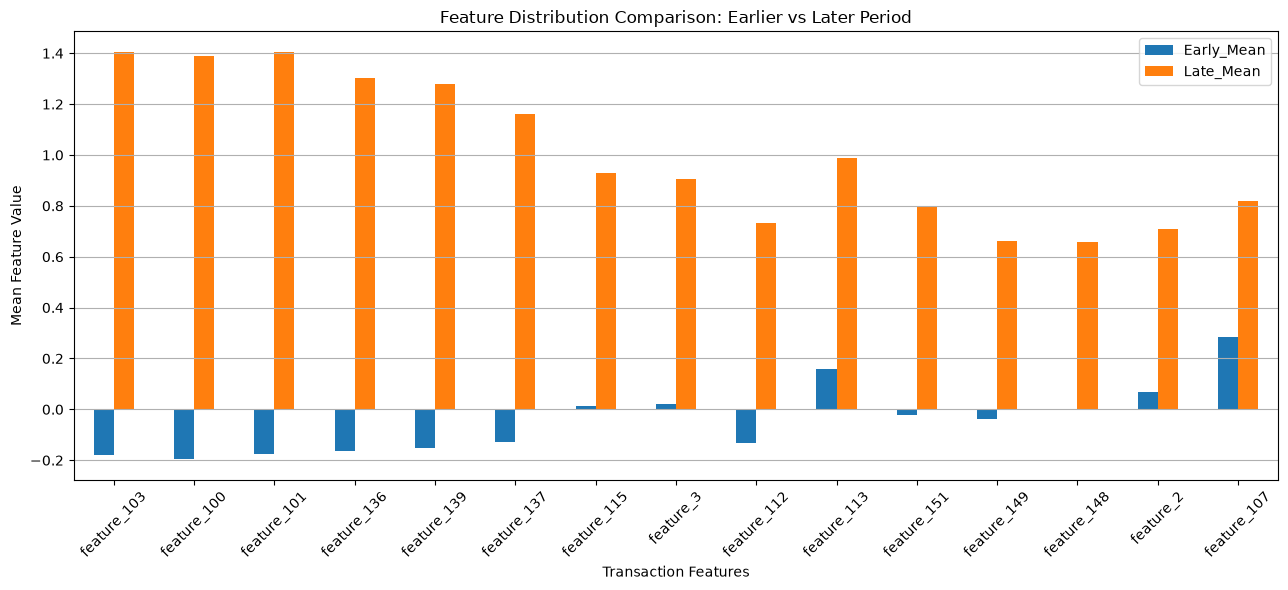

In [129]:
top_features = feature_comparison.head(15)

plt.figure(figsize=(12, 6))

top_features[["Early_Mean", "Late_Mean"]].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Feature Distribution Comparison: Earlier vs Later Period")
plt.xlabel("Transaction Features")
plt.ylabel("Mean Feature Value")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [130]:
early_illicit_rate = (
    (early_period["class"] == "1").mean() * 100
)

late_illicit_rate = (
    (late_period["class"] == "1").mean() * 100
)

print(f"Earlier period illicit rate: {early_illicit_rate:.2f}%")
print(f"Later period illicit rate: {late_illicit_rate:.2f}%")

Earlier period illicit rate: 10.97%
Later period illicit rate: 2.53%


In [131]:
top_features = feature_comparison.head(10).index.tolist()

class_feature_results = []

for label, class_name in [("1", "Illicit"), ("2", "Licit")]:

    early_class = early_period[
        early_period["class"] == label
    ]

    late_class = late_period[
        late_period["class"] == label
    ]

    for feature in top_features:

        class_feature_results.append({
            "Class": class_name,
            "Feature": feature,
            "Early Mean": early_class[feature].mean(),
            "Late Mean": late_class[feature].mean()
        })

class_feature_comparison = pd.DataFrame(
    class_feature_results
)

display(class_feature_comparison.round(4))

,Class,Feature,Early Mean,Late Mean
0,Illicit,feature_103,0.0341,1.5121
1,Illicit,feature_100,0.0399,1.4965
2,Illicit,feature_101,0.0307,1.5130
3,Illicit,feature_136,-0.0094,1.3942
4,Illicit,feature_139,-0.0534,1.3142
5,Illicit,feature_137,-0.1270,1.0978
6,Illicit,feature_115,0.1926,0.9796
7,Illicit,feature_3,0.1765,1.1335
8,Illicit,feature_112,0.2421,0.5628
9,Illicit,feature_113,0.1200,1.1309


In [132]:
from scipy.stats import ks_2samp

ks_results = []

for label, class_name in [("1", "Illicit"), ("2", "Licit")]:

    early_class = early_period[
        early_period["class"] == label
    ]

    late_class = late_period[
        late_period["class"] == label
    ]

    for feature in feature_columns_original:

        statistic, p_value = ks_2samp(
            early_class[feature],
            late_class[feature]
        )

        ks_results.append({
            "Class": class_name,
            "Feature": feature,
            "KS Statistic": statistic,
            "P Value": p_value
        })

ks_comparison = pd.DataFrame(ks_results)

ks_comparison = ks_comparison.sort_values(
    "P Value"
)

print("Top 20 features showing distribution differences:")
display(ks_comparison.head(20).round(6))

Top 20 features showing distribution differences:


,Class,Feature,KS Statistic,P Value
306,Licit,feature_142,0.370826,0.0
309,Licit,feature_145,0.265134,0.0
303,Licit,feature_139,0.947920,0.0
312,Licit,feature_148,0.343998,0.0
315,Licit,feature_151,0.375912,0.0
279,Licit,feature_115,0.380962,0.0
277,Licit,feature_113,0.288334,0.0
273,Licit,feature_109,0.370253,0.0
265,Licit,feature_101,0.998159,0.0
267,Licit,feature_103,0.992943,0.0


In [134]:
from scipy.stats import false_discovery_control

# Apply Benjamini-Hochberg correction
ks_comparison["Adjusted P Value"] = false_discovery_control(
    ks_comparison["P Value"].values,
    method="bh"
)

# Identify statistically significant features
significant_after_correction = ks_comparison[
    ks_comparison["Adjusted P Value"] < 0.05
]

print("Significant comparisons after FDR correction:")
print(len(significant_after_correction))

print("\nSignificant features by class:")
print(
    significant_after_correction.groupby("Class").size()
)

print("\nTop 15 features by KS statistic:")
display(
    ks_comparison.sort_values(
        "KS Statistic", ascending=False
    ).head(15).round(6)
)

Significant comparisons after FDR correction:
298

Significant features by class:
Class
Illicit    140
Licit      158
dtype: int64

Top 15 features by KS statistic:


,Class,Feature,KS Statistic,P Value,Adjusted P Value
100,Illicit,feature_101,1.000000,0.0,0.0
99,Illicit,feature_100,1.000000,0.0,0.0
102,Illicit,feature_103,1.000000,0.0,0.0
265,Licit,feature_101,0.998159,0.0,0.0
300,Licit,feature_136,0.994623,0.0,0.0
267,Licit,feature_103,0.992943,0.0,0.0
264,Licit,feature_100,0.991102,0.0,0.0
135,Illicit,feature_136,0.986974,0.0,0.0
138,Illicit,feature_139,0.978748,0.0,0.0
136,Illicit,feature_137,0.973035,0.0,0.0


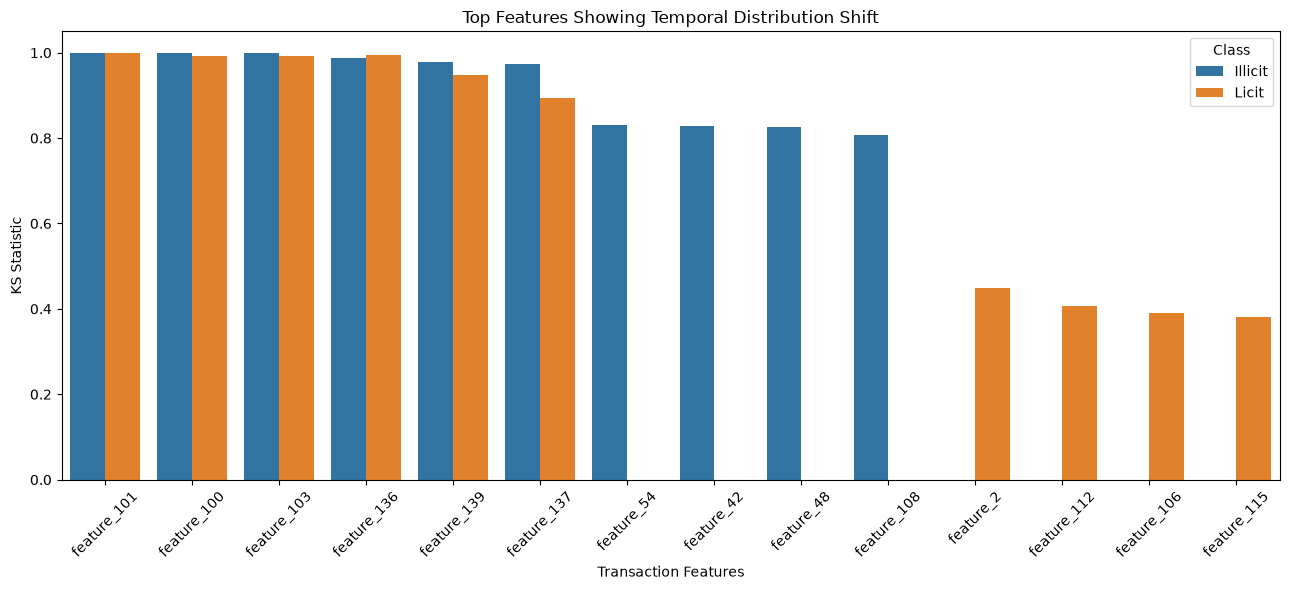

In [135]:
top_ks = (
    ks_comparison
    .sort_values("KS Statistic", ascending=False)
    .groupby("Class")
    .head(10)
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=top_ks,
    x="Feature",
    y="KS Statistic",
    hue="Class"
)

plt.title("Top Features Showing Temporal Distribution Shift")
plt.xlabel("Transaction Features")
plt.ylabel("KS Statistic")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [136]:
print(
    "Total comparisons:",
    len(ks_comparison)
)

print(
    "Significant after FDR correction:",
    (ks_comparison["Adjusted P Value"] < 0.05).sum()
)

print("\nSignificant comparisons by class:")

print(
    ks_comparison[
        ks_comparison["Adjusted P Value"] < 0.05
    ].groupby("Class").size()
)

Total comparisons: 330
Significant after FDR correction: 298

Significant comparisons by class:
Class
Illicit    140
Licit      158
dtype: int64


In [137]:
print("Original known dataset:", known_data.shape)
print("Hybrid dataset:", hybrid_data.shape)
print("Hybrid known dataset:", known_hybrid_gnn.shape)

print("\nOriginal model features:")
print("Number of features:", len(feature_columns))
print(feature_columns)

print("\nHybrid model features:")
print("Number of features:", len(hybrid_feature_columns))
print(hybrid_feature_columns)

Original known dataset: (46564, 168)
Hybrid dataset: (203769, 170)
Hybrid known dataset: (46564, 235)

Original model features:
Number of features: 168
['feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10', 'feature_11', 'feature_12', 'feature_13', 'feature_14', 'feature_15', 'feature_16', 'feature_17', 'feature_18', 'feature_19', 'feature_20', 'feature_21', 'feature_22', 'feature_23', 'feature_24', 'feature_25', 'feature_26', 'feature_27', 'feature_28', 'feature_29', 'feature_30', 'feature_31', 'feature_32', 'feature_33', 'feature_34', 'feature_35', 'feature_36', 'feature_37', 'feature_38', 'feature_39', 'feature_40', 'feature_41', 'feature_42', 'feature_43', 'feature_44', 'feature_45', 'feature_46', 'feature_47', 'feature_48', 'feature_49', 'feature_50', 'feature_51', 'feature_52', 'feature_53', 'feature_54', 'feature_55', 'feature_56', 'feature_57', 'feature_58', 'feature_59', 'feature_60', 'feature_61', 'f

In [138]:
print("Original dataset time steps:")
print(sorted(known_data["time_step"].unique()))

print("\nHybrid dataset time steps:")
print(sorted(known_hybrid_gnn["time_step"].unique()))

Original dataset time steps:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49)]

Hybrid dataset time steps:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int6

In [133]:
significant_features = ks_comparison[
    ks_comparison["P Value"] < 0.05
]

print("Total feature comparisons:", len(ks_comparison))

print(
    "Comparisons with p-value below 0.05:",
    len(significant_features)
)

print("\nSignificant comparisons by class:")

print(
    significant_features.groupby("Class").size()
)

Total feature comparisons: 330
Comparisons with p-value below 0.05: 298

Significant comparisons by class:
Class
Illicit    140
Licit      158
dtype: int64


In [32]:
import pandas as pd

edges = pd.read_csv(
    "../elliptic_bitcoin_dataset/elliptic_txs_edgelist.csv",
    header=None
)

edges.columns = ["txId1", "txId2"]

print("Edges dataset loaded successfully!")
print(edges.head())
print("Shape:", edges.shape)

Edges dataset loaded successfully!
       txId1      txId2
0      txId1      txId2
1  230425980    5530458
2  232022460  232438397
3  230460314  230459870
4  230333930  230595899
Shape: (234356, 2)


In [23]:
print("Features txId type:",
      features["txId"].dtype)

print("Classes txId type:",
      classes["txId"].dtype)

Features txId type: int64
Classes txId type: str


In [24]:

# Convert transaction IDs to strings
features["txId"] = features["txId"].astype(str).str.strip()

classes["txId"] = classes["txId"].astype(str).str.strip()

# Convert labels to strings
classes["class"] = classes["class"].astype(str).str.strip()

# Remove accidental header row, if present
classes = classes[
    classes["class"].str.lower() != "class"
].copy()

print("Transaction ID data types corrected!")

print("Features:", features["txId"].dtype)
print("Classes:", classes["txId"].dtype)


Transaction ID data types corrected!
Features: str
Classes: str


In [6]:
import pandas as pd
import os

DATA_PATH = "../elliptic_bitcoin_dataset"

classes = pd.read_csv(
    os.path.join(DATA_PATH, "elliptic_txs_classes.csv"),
    header=None
)

classes.columns = ["txId", "class"]

print("Classes dataset loaded successfully!")
display(classes.head())

Classes dataset loaded successfully!


,txId,class
0,txId,class
1,230425980,unknown
2,5530458,unknown
3,232022460,unknown
4,232438397,2


In [9]:

# Count transactions in each class
class_counts = classes["class"].value_counts()

print("Transaction Class Distribution")
print("--------------------------------")

print("Illicit transactions (1):",
      class_counts.get("1", 0))

print("Licit transactions (2):",
      class_counts.get("2", 0))

print("Unknown transactions:",
      class_counts.get("unknown", 0))

print("Total transactions:", class_counts.sum())
print(classes["class"].value_counts())
print(classes["class"].dtype)


Transaction Class Distribution
--------------------------------
Illicit transactions (1): 4545
Licit transactions (2): 42019
Unknown transactions: 157205
Total transactions: 203769
class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64
str


In [10]:
class_counts = classes["class"].value_counts()

print("Corrected Transaction Class Distribution")
print("-----------------------------------------")

print("Illicit transactions:", class_counts.get("1", 0))
print("Licit transactions:", class_counts.get("2", 0))
print("Unknown transactions:", class_counts.get("unknown", 0))

print("Total transactions:", class_counts.sum())

Corrected Transaction Class Distribution
-----------------------------------------
Illicit transactions: 4545
Licit transactions: 42019
Unknown transactions: 157205
Total transactions: 203769


In [11]:
class_percentages = (
    classes["class"].value_counts(normalize=True) * 100
)

print("Transaction Class Percentages:")
print(class_percentages.round(2))

Transaction Class Percentages:
class
unknown    77.15
2          20.62
1           2.23
Name: proportion, dtype: float64


Matplotlib is building the font cache; this may take a moment.


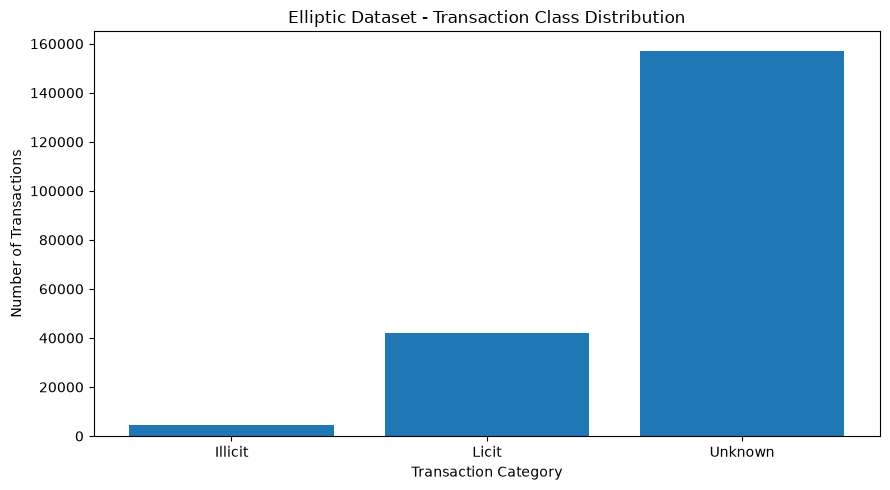

In [12]:
import matplotlib.pyplot as plt

labels = ["Illicit", "Licit", "Unknown"]

counts = [
    class_counts.get("1", 0),
    class_counts.get("2", 0),
    class_counts.get("unknown", 0)
]

plt.figure(figsize=(9, 5))

plt.bar(labels, counts)

plt.title("Elliptic Dataset - Transaction Class Distribution")
plt.xlabel("Transaction Category")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

In [15]:

# Display all feature column names
print("Total number of columns:", len(features.columns))

print("\nColumn names:")
print(features.columns.tolist())


Total number of columns: 167

Column names:
['txId', 'time_step', 'feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10', 'feature_11', 'feature_12', 'feature_13', 'feature_14', 'feature_15', 'feature_16', 'feature_17', 'feature_18', 'feature_19', 'feature_20', 'feature_21', 'feature_22', 'feature_23', 'feature_24', 'feature_25', 'feature_26', 'feature_27', 'feature_28', 'feature_29', 'feature_30', 'feature_31', 'feature_32', 'feature_33', 'feature_34', 'feature_35', 'feature_36', 'feature_37', 'feature_38', 'feature_39', 'feature_40', 'feature_41', 'feature_42', 'feature_43', 'feature_44', 'feature_45', 'feature_46', 'feature_47', 'feature_48', 'feature_49', 'feature_50', 'feature_51', 'feature_52', 'feature_53', 'feature_54', 'feature_55', 'feature_56', 'feature_57', 'feature_58', 'feature_59', 'feature_60', 'feature_61', 'feature_62', 'feature_63', 'feature_64', 'feature_65', 'feature_66', 'feature_67', 'feat

In [16]:
# Check missing values in the features dataset

missing_values = features.isnull().sum()

print("Total missing values:",
      missing_values.sum())

print("\nColumns with missing values:")
print(missing_values[missing_values > 0])

Total missing values: 0

Columns with missing values:
Series([], dtype: int64)


In [17]:
# Check duplicate transaction IDs

duplicate_ids = features["txId"].duplicated().sum()

print("Duplicate transaction IDs:", duplicate_ids)

Duplicate transaction IDs: 0


In [18]:
# Analyze transaction time steps

print("Number of unique time steps:",
      features["time_step"].nunique())

print("\nMinimum time step:",
      features["time_step"].min())

print("\nMaximum time step:",
      features["time_step"].max())

print("\nTransactions per time step:")

print(
    features["time_step"].value_counts().sort_index()
)

Number of unique time steps: 49

Minimum time step: 1

Maximum time step: 49

Transactions per time step:
time_step
1     7880
2     4544
3     6621
4     5693
5     6803
6     4328
7     6048
8     4457
9     4996
10    6727
11    4296
12    2047
13    4528
14    2022
15    3639
16    2975
17    3385
18    1976
19    3506
20    4291
21    3537
22    5894
23    4165
24    4592
25    2314
26    2523
27    1089
28    1653
29    4275
30    2483
31    2816
32    4525
33    3151
34    2486
35    5507
36    6393
37    3306
38    2891
39    2760
40    4481
41    5342
42    7140
43    5063
44    4975
45    5598
46    3519
47    5121
48    2954
49    2454
Name: count, dtype: int64


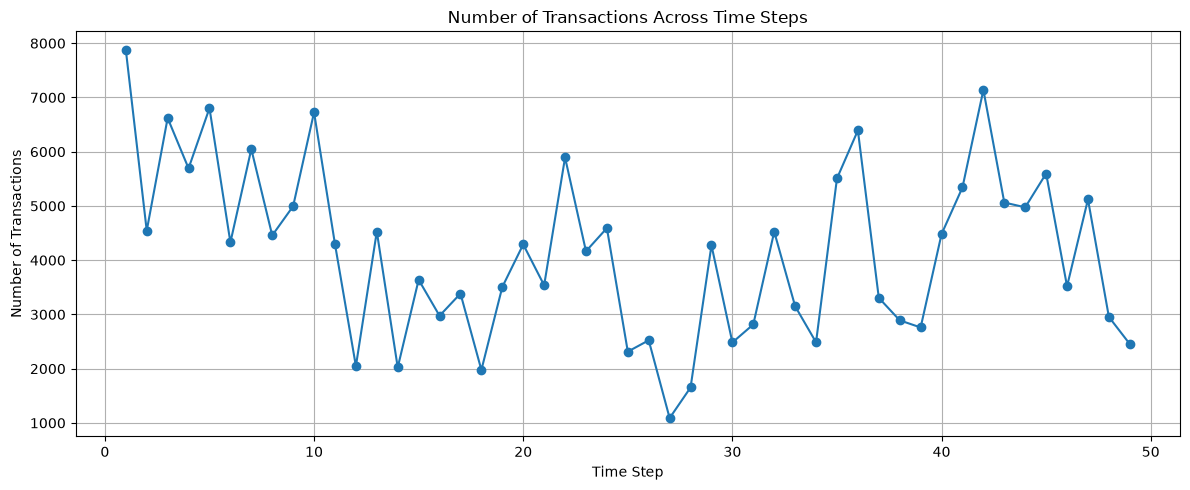

In [19]:
import matplotlib.pyplot as plt

# Count transactions in each time step
time_counts = features["time_step"].value_counts().sort_index()

plt.figure(figsize=(12, 5))

plt.plot(
    time_counts.index,
    time_counts.values,
    marker="o"
)

plt.title("Number of Transactions Across Time Steps")
plt.xlabel("Time Step")
plt.ylabel("Number of Transactions")

plt.grid(True)
plt.tight_layout()
plt.show()

In [20]:
# Select the 165 numerical features

numeric_features = features.drop(
    columns=["txId", "time_step"]
)

# Calculate statistical information

feature_statistics = numeric_features.describe()

display(feature_statistics)

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,...,feature_156,feature_157,feature_158,feature_159,feature_160,feature_161,feature_162,feature_163,feature_164,feature_165
count,2.037690e+05,203769.000000,2.037690e+05,2.037690e+05,2.037690e+05,2.037690e+05,2.037690e+05,2.037690e+05,2.037690e+05,2.037690e+05,...,2.037690e+05,2.037690e+05,2.037690e+05,2.037690e+05,2.037690e+05,2.037690e+05,2.037690e+05,2.037690e+05,2.037690e+05,2.037690e+05
mean,-8.926723e-18,0.000000,3.570689e-17,9.205683e-18,1.227424e-17,1.673761e-17,-4.463361e-18,-4.463361e-18,8.926723e-18,-6.974002e-19,...,-2.789601e-17,1.584493e-16,-8.034051e-17,8.034051e-17,4.463361e-18,-6.695042e-18,4.463361e-18,-1.785345e-17,-1.115840e-17,-5.356034e-17
std,1.000002e+00,1.000002,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,...,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00
min,-1.729826e-01,-0.210553,-1.756361e+00,-1.219696e-01,-6.372457e-02,-1.130020e-01,-6.158379e-02,-1.636459e-01,-1.694603e-01,-4.970696e-02,...,-5.770994e-01,-6.262286e-01,-9.790738e-01,-9.785560e-01,-2.160569e-01,-1.259391e-01,-1.311553e-01,-2.698175e-01,-1.760926e+00,-1.760984e+00
25%,-1.725317e-01,-0.180327,-1.201369e+00,-1.219696e-01,-4.387455e-02,-1.130020e-01,-6.158379e-02,-1.635168e-01,-1.690701e-01,-4.970696e-02,...,-5.696264e-01,-5.946915e-01,-9.790738e-01,-9.785560e-01,-9.888874e-02,-8.749016e-02,-1.311553e-01,-1.405971e-01,-1.206134e-01,-1.197925e-01
50%,-1.692045e-01,-0.132897,4.636092e-01,-1.219696e-01,-4.387455e-02,-1.130020e-01,-6.158379e-02,-1.620440e-01,-1.662255e-01,-4.970696e-02,...,-4.799511e-01,-4.559278e-01,2.411283e-01,2.414064e-01,1.827940e-02,-8.749016e-02,-1.311553e-01,-9.752359e-02,-1.206134e-01,-1.197925e-01
75%,-1.318553e-01,-0.055242,1.018602e+00,-1.219696e-01,-4.387455e-02,-1.130020e-01,-6.158379e-02,-1.355932e-01,-1.323665e-01,-4.970696e-02,...,1.552495e-01,1.212026e-01,1.305594e+00,1.398764e+00,1.827940e-02,-8.749016e-02,-8.467423e-02,-9.752359e-02,1.520067e-01,1.199710e-01
max,7.168197e+01,73.595052,2.683580e+00,4.902760e+01,2.600907e+02,5.456518e+01,1.134409e+02,7.335457e+01,7.231840e+01,1.891869e+02,...,7.862953e+00,7.914041e+00,1.461330e+00,1.461369e+00,1.170692e+02,2.518490e+02,2.387835e+02,1.057340e+02,1.519700e+00,1.521399e+00


In [14]:
import pandas as pd
import os

# Dataset folder path
DATA_PATH = "../elliptic_bitcoin_dataset"

# Load features dataset
features = pd.read_csv(
    os.path.join(DATA_PATH, "elliptic_txs_features.csv"),
    header=None
)

# Assign column names
features.columns = (
    ["txId", "time_step"] +
    [f"feature_{i}" for i in range(1, 166)]
)

print("Features dataset loaded successfully!")
print("Shape:", features.shape)

Features dataset loaded successfully!
Shape: (203769, 167)


In [8]:
# Remove the extra header row
classes = classes[
    classes["class"].astype(str).str.lower() != "class"
].copy()

print("Header row removed successfully!")

Header row removed successfully!


In [1]:
print("Graph-Based Fraud Detection Project")
print("Python environment connected successfully!")


Graph-Based Fraud Detection Project
Python environment connected successfully!


In [139]:
import xgboost as xgb

print("Searching for existing XGBoost models...\n")

found = False

for name, obj in list(globals().items()):

    if isinstance(obj, xgb.XGBClassifier):

        found = True

        print("Model variable:", name)
        print("Fitted:", hasattr(obj, "classes_"))
        print("Parameters:")

        print({
            key: obj.get_params()[key]
            for key in [
                "n_estimators",
                "max_depth",
                "learning_rate",
                "subsample",
                "colsample_bytree",
                "random_state"
            ]
        })

        print("-" * 50)

if not found:
    print("No XGBoost model objects currently available.")

Searching for existing XGBoost models...

Model variable: xgb_model
Fitted: True
Parameters:
{'n_estimators': 500, 'max_depth': 6, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'random_state': 42}
--------------------------------------------------
Model variable: hybrid_xgb_model
Fitted: True
Parameters:
{'n_estimators': 500, 'max_depth': 6, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'random_state': 42}
--------------------------------------------------


In [140]:
# Expanded historical training dataset

expanded_train = known_data[
    known_data["time_step"].between(1, 38)
].copy()

print("Expanded training shape:", expanded_train.shape)

print("\nClass distribution:")
print(expanded_train["class"].value_counts())

Expanded training shape: (34197, 168)

Class distribution:
class
2    30369
1     3828
Name: count, dtype: int64


In [141]:
# Use the same features as the original XGBoost model

X_expanded = expanded_train[feature_columns]

y_expanded = (
    expanded_train["class"] == "1"
).astype(int)

# Class balancing
expanded_scale_weight = (
    (y_expanded == 0).sum() /
    (y_expanded == 1).sum()
)

print("Expanded feature shape:", X_expanded.shape)
print("Expanded label shape:", y_expanded.shape)
print("Scale positive weight:", expanded_scale_weight)

KeyError: "['in_degree', 'out_degree', 'pagerank'] not in index"

In [142]:
print("Graph features columns:")
print(graph_features.columns.tolist())

print("\nGraph features shape:")
print(graph_features.shape)

Graph features columns:
['txId', 'in_degree', 'out_degree', 'pagerank']

Graph features shape:
(203769, 4)


In [143]:
expanded_train = known_data[
    known_data["time_step"].between(1, 38)
].copy()

expanded_train = expanded_train.merge(
    graph_features,
    on="txId",
    how="left",
    validate="one_to_one"
)

print("Expanded training shape:", expanded_train.shape)

print("\nMissing graph features:")
print(
    expanded_train[
        ["in_degree", "out_degree", "pagerank"]
    ].isnull().sum()
)

Expanded training shape: (34197, 171)

Missing graph features:
in_degree     0
out_degree    0
pagerank      0
dtype: int64


In [144]:
X_expanded = expanded_train[feature_columns]

y_expanded = (
    expanded_train["class"] == "1"
).astype(int)

print("X shape:", X_expanded.shape)
print("y shape:", y_expanded.shape)

print("\nClass distribution:")
print(y_expanded.value_counts())

X shape: (34197, 168)
y shape: (34197,)

Class distribution:
class
0    30369
1     3828
Name: count, dtype: int64


In [145]:
expanded_scale_weight = (
    (y_expanded == 0).sum() /
    (y_expanded == 1).sum()
)

print("Scale positive weight:", expanded_scale_weight)

Scale positive weight: 7.933385579937304


In [146]:
expanded_xgb_model = xgb.XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=expanded_scale_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

expanded_xgb_model.fit(
    X_expanded,
    y_expanded,
    verbose=False
)

print("Expanded-history XGBoost trained successfully!")

Expanded-history XGBoost trained successfully!


In [147]:
X_test_expanded = test_data[feature_columns]

y_test_expanded = (
    test_data["class"] == "1"
).astype(int)

prob_expanded = expanded_xgb_model.predict_proba(
    X_test_expanded
)[:, 1]

pred_expanded = (prob_expanded >= 0.5).astype(int)

print("Classification Report:")
print(
    classification_report(
        y_test_expanded,
        pred_expanded,
        target_names=["Licit", "Illicit"]
    )
)

print(
    "Average Precision:",
    average_precision_score(
        y_test_expanded,
        prob_expanded
    )
)

Classification Report:
              precision    recall  f1-score   support

       Licit       0.98      1.00      0.99     11650
     Illicit       0.94      0.65      0.77       717

    accuracy                           0.98     12367
   macro avg       0.96      0.82      0.88     12367
weighted avg       0.98      0.98      0.98     12367

Average Precision: 0.8088929429396907


In [148]:
# Prepare test data
X_test_expanded = test_data[feature_columns]

y_test_expanded = (
    test_data["class"] == "1"
).astype(int)

# Predict probabilities
prob_expanded = expanded_xgb_model.predict_proba(
    X_test_expanded
)[:, 1]

# Convert probabilities into predictions
pred_expanded = (prob_expanded >= 0.5).astype(int)

# Evaluation
print("EXPANDED XGBOOST RESULTS")
print("-" * 40)

print(classification_report(
    y_test_expanded,
    pred_expanded,
    target_names=["Licit", "Illicit"]
))

expanded_ap = average_precision_score(
    y_test_expanded,
    prob_expanded
)

print("Average Precision:", round(expanded_ap, 4))

EXPANDED XGBOOST RESULTS
----------------------------------------
              precision    recall  f1-score   support

       Licit       0.98      1.00      0.99     11650
     Illicit       0.94      0.65      0.77       717

    accuracy                           0.98     12367
   macro avg       0.96      0.82      0.88     12367
weighted avg       0.98      0.98      0.98     12367

Average Precision: 0.8089


In [149]:
# Original XGBoost predictions on the same test data
prob_original = xgb_model.predict_proba(
    X_test_expanded
)[:, 1]

pred_original = (prob_original >= 0.5).astype(int)

# Calculate metrics
comparison_results = pd.DataFrame({
    "Model": [
        "Original XGBoost",
        "Expanded XGBoost"
    ],
    "Precision": [
        precision_score(y_test_expanded, pred_original),
        precision_score(y_test_expanded, pred_expanded)
    ],
    "Recall": [
        recall_score(y_test_expanded, pred_original),
        recall_score(y_test_expanded, pred_expanded)
    ],
    "F1 Score": [
        f1_score(y_test_expanded, pred_original),
        f1_score(y_test_expanded, pred_expanded)
    ],
    "Average Precision": [
        average_precision_score(y_test_expanded, prob_original),
        average_precision_score(y_test_expanded, prob_expanded)
    ]
})

comparison_results.round(4)

,Model,Precision,Recall,F1 Score,Average Precision
0,Original XGBoost,0.6967,0.6471,0.6710,0.6983
1,Expanded XGBoost,0.9433,0.6499,0.7696,0.8089


Confusion Matrix:
[[11622    28]
 [  251   466]]

Prediction Analysis:
Correctly identified licit: 11622
Incorrectly flagged licit: 28
Correctly detected illicit: 466
Missed illicit transactions: 251


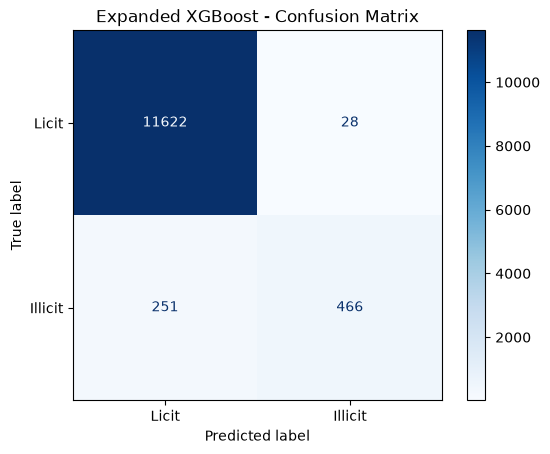

In [150]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test_expanded,
    pred_expanded
)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nPrediction Analysis:")
print("Correctly identified licit:", tn)
print("Incorrectly flagged licit:", fp)
print("Correctly detected illicit:", tp)
print("Missed illicit transactions:", fn)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Licit", "Illicit"]
).plot(cmap="Blues", values_format="d")

plt.title("Expanded XGBoost - Confusion Matrix")
plt.show()

         Feature  Importance
52    feature_53    0.088950
45    feature_46    0.084009
39    feature_40    0.072533
89    feature_90    0.064038
162  feature_163    0.048384
58    feature_59    0.045391
4      feature_5    0.034382
40    feature_41    0.032354
54    feature_55    0.025928
64    feature_65    0.024920
79    feature_80    0.019359
131  feature_132    0.015347
48    feature_49    0.014217
160  feature_161    0.013048
80    feature_81    0.012721
66    feature_67    0.012436
46    feature_47    0.011934
152  feature_153    0.011807
151  feature_152    0.010855
99   feature_100    0.008045


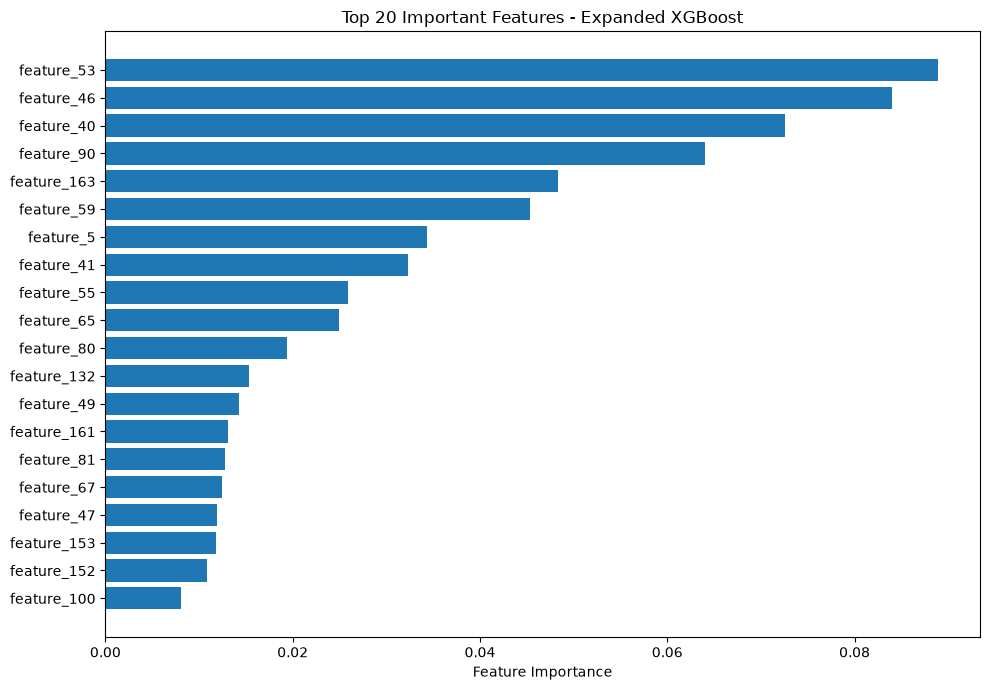

In [151]:
feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": expanded_xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(20))

plt.figure(figsize=(10, 7))

top_features = feature_importance.head(20).sort_values(
    by="Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.title("Top 20 Important Features - Expanded XGBoost")
plt.tight_layout()
plt.show()

In [152]:
graph_feature_importance = feature_importance[
    feature_importance["Feature"].isin(
        ["in_degree", "out_degree", "pagerank"]
    )
]

print("Graph Feature Importance:")
print(graph_feature_importance)

print("\nTop 20 feature names:")
print(feature_importance.head(20)["Feature"].tolist())

Graph Feature Importance:
        Feature  Importance
165   in_degree    0.001713
167    pagerank    0.001572
166  out_degree    0.000860

Top 20 feature names:
['feature_53', 'feature_46', 'feature_40', 'feature_90', 'feature_163', 'feature_59', 'feature_5', 'feature_41', 'feature_55', 'feature_65', 'feature_80', 'feature_132', 'feature_49', 'feature_161', 'feature_81', 'feature_67', 'feature_47', 'feature_153', 'feature_152', 'feature_100']


In [4]:
# Map each transaction ID to its time step
tx_time = features[["txId", "time_step"]].copy()

# Attach time steps to both ends of every edge
edge_time = edges.merge(
    tx_time,
    left_on="txId1",
    right_on="txId",
    how="left"
).rename(columns={"time_step": "source_time"})

edge_time = edge_time.drop(columns=["txId"])

edge_time = edge_time.merge(
    tx_time,
    left_on="txId2",
    right_on="txId",
    how="left"
).rename(columns={"time_step": "target_time"})

edge_time = edge_time.drop(columns=["txId"])

# Count edge categories
print("Total edges:", len(edge_time))

print(
    "Training-period edges (both endpoints <= 38):",
    (
        (edge_time["source_time"] <= 38) &
        (edge_time["target_time"] <= 38)
    ).sum()
)

print(
    "Test-period edges (both endpoints >= 39):",
    (
        (edge_time["source_time"] >= 39) &
        (edge_time["target_time"] >= 39)
    ).sum()
)

print(
    "Cross-period edges:",
    (
        (edge_time["source_time"] <= 38) &
        (edge_time["target_time"] >= 39)
    ).sum()
    +
    (
        (edge_time["source_time"] >= 39) &
        (edge_time["target_time"] <= 38)
    ).sum()
)

Total edges: 234355
Training-period edges (both endpoints <= 38): 177950
Test-period edges (both endpoints >= 39): 56405
Cross-period edges: 0


In [2]:
import pandas as pd
import numpy as np
import networkx as nx
from pathlib import Path

# Find the dataset folder
possible_paths = [
    Path("elliptic_bitcoin_dataset"),
    Path("../elliptic_bitcoin_dataset")
]

dataset_path = next(
    (p for p in possible_paths if p.exists()),
    None
)

if dataset_path is None:
    raise FileNotFoundError("Dataset folder not found.")

# Load datasets
features = pd.read_csv(
    dataset_path / "elliptic_txs_features.csv",
    header=None
)

edges = pd.read_csv(
    dataset_path / "elliptic_txs_edgelist.csv",
    header=None
)

classes = pd.read_csv(
    dataset_path / "elliptic_txs_classes.csv",
    header=None
)

# Assign column names
features.columns = (
    ["txId", "time_step"] +
    [f"feature_{i}" for i in range(1, 166)]
)

edges.columns = ["txId1", "txId2"]
classes.columns = ["txId", "class"]

# Remove accidental header row
classes = classes[
    classes["class"].astype(str).str.lower() != "class"
].copy()

# Normalize transaction IDs
features["txId"] = features["txId"].astype(str).str.strip()
edges["txId1"] = edges["txId1"].astype(str).str.strip()
edges["txId2"] = edges["txId2"].astype(str).str.strip()
classes["txId"] = classes["txId"].astype(str).str.strip()

# Remove accidental edge header row
edges = edges[
    (edges["txId1"] != "txId1") &
    (edges["txId2"] != "txId2")
].copy()

print("All datasets reloaded successfully!")
print("Features:", features.shape)
print("Edges:", edges.shape)
print("Classes:", classes.shape)

All datasets reloaded successfully!
Features: (203769, 167)
Edges: (234355, 2)
Classes: (203769, 2)


In [3]:
print("Features available:", "features" in globals())
print("Edges available:", "edges" in globals())

print("\nFirst five transactions:")
display(features.head())

Features available: True
Edges available: True

First five transactions:


,txId,time_step,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,...,feature_156,feature_157,feature_158,feature_159,feature_160,feature_161,feature_162,feature_163,feature_164,feature_165
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.947382,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.670883,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.577099,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.511871,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117


In [5]:
# Create directed transaction graph
G = nx.from_pandas_edgelist(
    edges,
    source="txId1",
    target="txId2",
    create_using=nx.DiGraph()
)

# Include all transactions as nodes
G.add_nodes_from(features["txId"])

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

# Calculate graph features
graph_features = pd.DataFrame({
    "txId": list(G.nodes()),
    "in_degree": [G.in_degree(n) for n in G.nodes()],
    "out_degree": [G.out_degree(n) for n in G.nodes()],
    "pagerank": list(nx.pagerank(G).values())
})

print("\nGraph features recreated:", graph_features.shape)

Nodes: 203769
Edges: 234355

Graph features recreated: (203769, 4)


In [6]:
# Identify known test-period transactions
known_data = features.merge(
    classes,
    on="txId",
    how="inner"
)

known_data = known_data[
    known_data["class"].isin(["1", "2"])
].copy()

test_ids = set(
    known_data.loc[
        known_data["time_step"].between(39, 49),
        "txId"
    ]
)

test_graph_features = graph_features[
    graph_features["txId"].isin(test_ids)
]

print("Test transactions:", len(test_ids))

print("\nTest graph feature summary:")
display(
    test_graph_features[
        ["in_degree", "out_degree", "pagerank"]
    ].describe()
)

Test transactions: 12367

Test graph feature summary:


,in_degree,out_degree,pagerank
count,12367.000000,12367.000000,12367.000000
mean,2.013504,1.243551,0.000006
std,8.445939,1.887385,0.000019
min,0.000000,0.000000,0.000002
25%,0.000000,1.000000,0.000002
50%,1.000000,1.000000,0.000002
75%,1.000000,1.000000,0.000004
max,188.000000,99.000000,0.000461


In [7]:
print("Expanded XGBoost model:",
      "expanded_xgb_model" in globals())

print("Feature columns:",
      "feature_columns" in globals())

print("Graph features:",
      "graph_features" in globals())

print("Pandas:",
      pd.__version__)

Expanded XGBoost model: False
Feature columns: False
Graph features: True
Pandas: 3.1.1


In [9]:
import pandas as pd
import numpy as np
import xgboost as xgb
import joblib

from sklearn.metrics import (
    classification_report,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# Recreate feature column names
feature_columns = (
    [f"feature_{i}" for i in range(1, 166)] +
    ["in_degree", "out_degree", "pagerank"]
)

# Merge transaction features and graph features
hybrid_data = features.merge(
    graph_features,
    on="txId",
    how="left",
    validate="one_to_one"
)

# Attach class labels
known_data = hybrid_data.merge(
    classes,
    on="txId",
    how="inner",
    validate="one_to_one"
)

# Keep only labelled transactions
known_data = known_data[
    known_data["class"].isin(["1", "2"])
].copy()

# Select training period: time steps 1–38
expanded_train = known_data[
    known_data["time_step"].between(1, 38)
].copy()

X_expanded = expanded_train[feature_columns]

y_expanded = (
    expanded_train["class"] == "1"
).astype(int)

print("Training data:", X_expanded.shape)
print("Labels:", y_expanded.shape)
print("Feature columns:", len(feature_columns))

Training data: (34197, 168)
Labels: (34197,)
Feature columns: 168


In [10]:
expanded_scale_weight = (
    (y_expanded == 0).sum() /
    (y_expanded == 1).sum()
)

expanded_xgb_model = xgb.XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=expanded_scale_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

expanded_xgb_model.fit(
    X_expanded,
    y_expanded,
    verbose=False
)

print("Expanded XGBoost retrained successfully!")

Expanded XGBoost retrained successfully!


In [11]:
joblib.dump(
    expanded_xgb_model,
    "expanded_xgb_model.pkl"
)

joblib.dump(
    feature_columns,
    "feature_columns.pkl"
)

print("Model and feature columns saved successfully!")

Model and feature columns saved successfully!


In [12]:
expanded_scale_weight = (
    (y_expanded == 0).sum() /
    (y_expanded == 1).sum()
)

expanded_xgb_model = xgb.XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=expanded_scale_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

expanded_xgb_model.fit(
    X_expanded,
    y_expanded,
    verbose=False
)

print("Expanded XGBoost retrained successfully!")

Expanded XGBoost retrained successfully!


In [13]:
import joblib

joblib.dump(
    expanded_xgb_model,
    "expanded_xgb_model.pkl"
)

joblib.dump(
    feature_columns,
    "feature_columns.pkl"
)

print("Model saved successfully!")
print("Feature columns saved successfully!")

Model saved successfully!
Feature columns saved successfully!


In [14]:
import os

print("Model file exists:",
      os.path.exists("expanded_xgb_model.pkl"))

print("Feature file exists:",
      os.path.exists("feature_columns.pkl"))

Model file exists: True
Feature file exists: True


In [15]:
joblib.dump(
    graph_features,
    "graph_features.pkl"
)

print("Graph features saved successfully!")

Graph features saved successfully!
